# Controlled Matched-Provenance Monte Carlo Train/Test Evaluation

This notebook extends the controlled matched-star analyses in `analyze_comprehensive` by evaluating SPOC–TESSCut and QLP–TESSCut comparisons across repeated stratified random train/test splits.

## Evaluation design

The controlled matched datasets are substantially smaller than the full TESS dataset, particularly the SPOC–TESSCut sample. The adopted design therefore uses **repeated stratified Monte Carlo train/test evaluation** with a 70/30 split rather than dividing the matched samples into separate training, validation, and test subsets. The feature definitions, retained feature set, preprocessing procedure, Random Forest configuration, split ratio, number of iterations, and reported metrics are fixed independently of the repeated held-out results.

For every iteration:

- matched `VSXId` objects are divided into 70% training and 30% held-out test subsets;
- stratification preserves the variable-star family distribution as far as the sample permits;
- identical star-level assignments are used for the official product and TESSCut;
- the same Random Forest seed is used for both provenance models;
- all iterations and metrics are retained.

The notebook reports repeated predictive-performance differences, repeated permutation-importance stability, observational-feature ablation, paired per-class errors, and the manuscript tables and figures derived from these controlled analyses. The empirical split distributions quantify sensitivity to alternative train/test assignments and are not treated as independent-sample confidence intervals.


## 1. Imports and fixed analysis configuration

The analysis preserves the 100 repeated 70/30 stratified splits with seeds 42–141. Full-feature models, held-out permutation importance, and metadata ablation are recomputed by default. Setting a run flag to `False` opts into cache reuse; the saved outputs must match the corrected feature files, eligibility policy, frozen feature schema, model configuration, and output hashes.

Keep `tess_research_validation.py` in the notebook working directory. Rerun the corrected feature producers before this notebook; original feature caches without the corrected Lomb–Scargle false-alarm-probability manifest are rejected.


In [25]:
from pathlib import Path
import os
import json
import platform
import sys
import time

import tess_research_validation as trv

import numpy as np
import pandas as pd
import sklearn

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

Project_Root = Path(
    os.environ.get("Project_Root", "/data/projects/TESS_Research_Publication")
)

# Inputs used by the controlled matched-provenance analysis.
SPOC_TESSCUT_FEATURE_PATH = (
    Project_Root / "data" / "SPOC_TESSCutCache" / "SPOC_TESSCut_features_QC.parquet"
)
QLP_TESSCUT_FEATURE_PATH = (
    Project_Root / "data" / "QLP_TESSCutCache" / "QLP_TESSCut_features_QC.parquet"
)

OUTPUT_DIR = Project_Root / "results" / "controlled_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMN = "family"
STATUS_COLUMN = "FeatureStatus"
MIN_CADENCES = 100
ANALYSIS_CACHE_VERSION = "controlled_monte_carlo_strict_pairs_v1"

# Prespecified Monte Carlo design.
RUN_MONTE_CARLO = False #True
N_SPLITS = 100
TEST_SIZE = 0.30
BASE_RANDOM_SEED = 42
SPLIT_SEEDS = np.arange(BASE_RANDOM_SEED, BASE_RANDOM_SEED + N_SPLITS, dtype=int)

# Repeated permutation-importance design. These settings are prespecified before
# examining the repeated importance results. Twenty evenly spaced Monte Carlo
# splits balance stability assessment with computational cost.
RUN_REPEATED_PERMUTATION_IMPORTANCE = True
PERMUTATION_SPLIT_COUNT = 20
PERMUTATION_N_REPEATS = 10
PERMUTATION_SCORING = "balanced_accuracy"
# Keep this at 1 because Random Forest prediction already uses RF_N_JOBS cores.
# Parallelizing both levels would oversubscribe the same CPU cores.
PERMUTATION_N_JOBS = 1

if not 1 <= PERMUTATION_SPLIT_COUNT <= N_SPLITS:
    raise ValueError("PERMUTATION_SPLIT_COUNT must be between 1 and N_SPLITS.")
PERMUTATION_SPLIT_INDICES = np.linspace(
    0, N_SPLITS - 1, PERMUTATION_SPLIT_COUNT, dtype=int
)
PERMUTATION_SPLIT_SEEDS = [
    int(SPLIT_SEEDS[index]) for index in PERMUTATION_SPLIT_INDICES
]
PERMUTATION_SPLIT_SEED_SET = set(PERMUTATION_SPLIT_SEEDS)

# Use all available CPU cores inside each Random Forest fit. The outer Monte
# Carlo loop remains sequential to avoid oversubscribing the same cores and
# duplicating the matched datasets across concurrent jobs.
RF_N_JOBS = 24

# Fixed Random Forest configuration from Steps 21–23.
RF_PARAMETERS = {
    "n_estimators": 500,
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "class_weight": "balanced_subsample",
    "n_jobs": RF_N_JOBS,
}

print(f"Output directory: {OUTPUT_DIR}")
print(f"Run Monte Carlo simulation: {RUN_MONTE_CARLO}")
print(f"Random Forest n_jobs: {RF_N_JOBS} (-1 means all available CPU cores)")
print(f"Monte Carlo iterations: {N_SPLITS}")
print(f"Run repeated permutation importance: {RUN_REPEATED_PERMUTATION_IMPORTANCE}")
print(f"Permutation-importance split count: {PERMUTATION_SPLIT_COUNT}")
print(f"Permutation repeats per feature/model: {PERMUTATION_N_REPEATS}")
print(f"Permutation scoring: {PERMUTATION_SCORING}")
print(f"Permutation split seeds: {PERMUTATION_SPLIT_SEEDS}")
print(f"Train/test fraction: {1.0 - TEST_SIZE:.0%}/{TEST_SIZE:.0%}")
print(f"Split seeds: {SPLIT_SEEDS[0]} through {SPLIT_SEEDS[-1]}")


Output directory: /data/projects/TESS_Research_Publication/results/controlled_analysis
Run Monte Carlo simulation: False
Random Forest n_jobs: 24 (-1 means all available CPU cores)
Monte Carlo iterations: 100
Run repeated permutation importance: True
Permutation-importance split count: 20
Permutation repeats per feature/model: 10
Permutation scoring: balanced_accuracy
Permutation split seeds: [42, 47, 52, 57, 62, 68, 73, 78, 83, 88, 94, 99, 104, 109, 114, 120, 125, 130, 135, 141]
Train/test fraction: 70%/30%
Split seeds: 42 through 141


## 2. Load the frozen shared predictor schema

The 39 predictors are frozen to the schema shared by notebooks 03–08. No new Spearman filter is fitted to a different feature table in this notebook. This keeps the scientific corrections limited to strict pair eligibility and the frequency-bound false-alarm probability, rather than also changing the model inputs. The exact ordered list is saved with the run configuration and outputs.


In [26]:
FEATURE_COLUMNS = list(trv.FEATURE_COLUMNS)
if len(FEATURE_COLUMNS) != 39 or len(set(FEATURE_COLUMNS)) != len(FEATURE_COLUMNS):
    raise ValueError("The shared frozen feature schema must contain 39 distinct predictors.")
if "ProvenanceScore" in FEATURE_COLUMNS:
    raise ValueError("ProvenanceScore must not be a classifier predictor.")

pd.DataFrame({"Feature": FEATURE_COLUMNS}).to_csv(
    OUTPUT_DIR / "fixed_feature_columns.csv", index=False
)
print(f"Frozen shared predictor count: {len(FEATURE_COLUMNS)}")
print(f"Scientific correction version: {trv.SCIENCE_FIX_VERSION}")
display(pd.DataFrame({"Feature": FEATURE_COLUMNS}))


Frozen shared predictor count: 39
Scientific correction version: eligibility_fap_v1


,Feature
0,QualityScore
1,OriginalFluxMedian
2,OriginalFluxStd
3,CadenceCount
4,TimeSpanDays
5,MedianCadenceDays
6,FluxStd
7,FluxMedian
8,FluxMad
9,FluxP05


## 3. Prepare controlled matched pairs

Both official and TESSCut rows must have `FeatureStatus == "ok"` and a finite numeric `CadenceCount >= 100` **before** pairs are formed. The feature caches must carry the corrected false-alarm-probability manifest. Missing object identifiers and family labels are excluded. Exactly one eligible row from each provenance is required for each `VSXId`; family labels must agree within each pair. Classes with fewer than two matched objects are excluded before stratification. Counts and exclusions are derived from the current inputs rather than fixed to a historical sample size.


In [27]:
def normalize_provenance_label(value):
    text = str(value).strip().upper().replace("_", "").replace("-", "")
    if "SPOC" in text:
        return "SPOC"
    if "QLP" in text:
        return "QLP"
    if "TESSCUT" in text:
        return "TESSCut"
    return str(value).strip()


def resolve_provenance_column(df):
    for column in ["Provenance", "provenance", "Source", "source"]:
        if column in df.columns:
            return column
    raise KeyError("Could not find a provenance/source column.")


PAIR_ELIGIBILITY_AUDIT = []


def prepare_matched_pair(feature_file, official_provenance):
    # Reject legacy/stale FAP caches before any model input is selected.
    df = trv.read_corrected_features(feature_file)
    required = {"VSXId", TARGET_COLUMN}
    missing = sorted(required - set(df.columns))
    if missing:
        raise KeyError(f"Matched feature table is missing required columns: {missing}")
    trv.require_feature_schema(df, columns=FEATURE_COLUMNS)
    provenance_column = resolve_provenance_column(df)
    df["_ProvenanceNormalized"] = df[provenance_column].map(normalize_provenance_label)
    df = df[df["_ProvenanceNormalized"].isin({official_provenance, "TESSCut"})].copy()
    raw_row_count = len(df)

    # Apply exactly the same successful-extraction/cadence rule to both sides,
    # before counting or selecting matched object pairs.
    df = trv.eligible_rows(df, min_cadences=MIN_CADENCES)
    eligible_row_count = len(df)
    identifiers = df["VSXId"].astype("string").str.strip()
    families = df[TARGET_COLUMN].astype("string").str.strip()
    valid_identity = identifiers.notna() & identifiers.ne("") & families.notna() & families.ne("")
    df = df.loc[valid_identity].copy()
    df["VSXId"] = identifiers.loc[valid_identity].astype(str)
    df[TARGET_COLUMN] = families.loc[valid_identity].astype(str)
    identified_row_count = len(df)

    pair_counts = df.groupby(["VSXId", "_ProvenanceNormalized"]).size().unstack(fill_value=0)
    for provenance in [official_provenance, "TESSCut"]:
        if provenance not in pair_counts.columns:
            pair_counts[provenance] = 0
    valid_ids = pair_counts.index[
        pair_counts[official_provenance].eq(1) & pair_counts["TESSCut"].eq(1)
    ]
    matched = df[df["VSXId"].isin(valid_ids)].copy()
    official_df = matched[matched["_ProvenanceNormalized"].eq(official_provenance)].set_index("VSXId", drop=False).sort_index()
    tesscut_df = matched[matched["_ProvenanceNormalized"].eq("TESSCut")].set_index("VSXId", drop=False).sort_index()
    if not official_df.index.equals(tesscut_df.index):
        raise AssertionError("Pair formation did not produce identical ordered object IDs.")
    mismatch = official_df[TARGET_COLUMN].ne(tesscut_df[TARGET_COLUMN])
    if mismatch.any():
        bad_ids = official_df.index[mismatch].tolist()
        raise ValueError(f"{official_provenance}–TESSCut family-label mismatches: {len(bad_ids)}; examples={bad_ids[:10]}")

    class_counts_before = official_df[TARGET_COLUMN].value_counts()
    keep_classes = class_counts_before[class_counts_before >= 2].index
    keep_ids = official_df.index[official_df[TARGET_COLUMN].isin(keep_classes)]
    official_df = official_df.loc[keep_ids].copy()
    tesscut_df = tesscut_df.loc[keep_ids].copy()
    if official_df.empty:
        raise ValueError(f"No eligible stratifiable {official_provenance}–TESSCut pairs remain.")
    for provenance_df in [official_df, tesscut_df]:
        trv.assert_eligible(provenance_df, min_cadences=MIN_CADENCES)
        trv.require_feature_schema(provenance_df, columns=FEATURE_COLUMNS)
        provenance_df[FEATURE_COLUMNS] = provenance_df[FEATURE_COLUMNS].apply(pd.to_numeric, errors="raise")
        if np.isinf(provenance_df[FEATURE_COLUMNS].to_numpy(dtype=float)).any():
            raise ValueError("Infinite predictor values remain in the corrected feature cache.")

    PAIR_ELIGIBILITY_AUDIT.append({
        "Comparison": f"{official_provenance}_vs_TESSCut",
        "FeatureFile": str(feature_file),
        "InputRowsForComparedProvenances": int(raw_row_count),
        "RowsPassingStatusAndCadences": int(eligible_row_count),
        "RowsExcludedByStatusOrCadences": int(raw_row_count - eligible_row_count),
        "RowsExcludedByMissingIdOrFamily": int(eligible_row_count - identified_row_count),
        "StrictOnePerProvenancePairsBeforeClassFilter": int(len(valid_ids)),
        "PairsExcludedBySmallClasses": int(len(valid_ids) - len(official_df)),
        "MatchedObjectsUsed": int(len(official_df)),
    })
    return official_df, tesscut_df, official_df[TARGET_COLUMN].value_counts()


SPOC_DF, SPOC_TESSCUT_DF, SPOC_CLASS_COUNTS = prepare_matched_pair(SPOC_TESSCUT_FEATURE_PATH, "SPOC")
QLP_DF, QLP_TESSCUT_DF, QLP_CLASS_COUNTS = prepare_matched_pair(QLP_TESSCUT_FEATURE_PATH, "QLP")
PAIR_ELIGIBILITY_AUDIT_DF = pd.DataFrame(PAIR_ELIGIBILITY_AUDIT)
PAIR_ELIGIBILITY_AUDIT_DF.to_csv(OUTPUT_DIR / "matched_pair_eligibility_audit.csv", index=False)
print(f"SPOC–TESSCut matched objects used: {len(SPOC_DF):,}")
display(SPOC_CLASS_COUNTS.rename("MatchedCount"))
print(f"QLP–TESSCut matched objects used: {len(QLP_DF):,}")
display(QLP_CLASS_COUNTS.rename("MatchedCount"))
display(PAIR_ELIGIBILITY_AUDIT_DF)


SPOC–TESSCut matched objects used: 506


family
LONG_PERIOD        117
CV                 114
YSO                 92
CEPHEID             64
DSCT_SXPHE          51
ELLIPSOIDAL_ROT     29
XRAY                20
ECLIPSING           14
RRLYR                5
Name: MatchedCount, dtype: int64

QLP–TESSCut matched objects used: 1,353


family
LONG_PERIOD        487
CEPHEID            233
DSCT_SXPHE         211
ELLIPSOIDAL_ROT    151
YSO                132
ECLIPSING          110
RRLYR               17
XRAY                10
CV                   2
Name: MatchedCount, dtype: int64

,Comparison,FeatureFile,InputRowsForComparedProvenances,RowsPassingStatusAndCadences,RowsExcludedByStatusOrCadences,RowsExcludedByMissingIdOrFamily,StrictOnePerProvenancePairsBeforeClassFilter,PairsExcludedBySmallClasses,MatchedObjectsUsed
0,SPOC_vs_TESSCut,/data/projects/TESS_Research_Publication/data/...,1012,1012,0,0,506,0,506
1,QLP_vs_TESSCut,/data/projects/TESS_Research_Publication/data/...,2721,2719,2,0,1353,0,1353


## 4. Monte Carlo simulation functions

Each iteration creates one stratified object-level split and applies it unchanged to both provenances. Median imputation is fitted independently inside each training pipeline. No test observation is used to fit the imputer or classifier.

The notebook saves:

- one paired summary row per split and provenance comparison;
- long-format train/test performance metrics;
- per-family held-out precision, recall, F1, and support;
- prediction-level paired records for subsequent McNemar, bootstrap, or error analysis;
- Random Forest built-in feature importance for every split and provenance;
- repeated held-out permutation importance on 20 prespecified splits, including every raw permutation repeat;
- class counts and exact train/test object assignments for every iteration.

### Repeated permutation-importance design

Permutation importance is evaluated only on held-out test data and uses balanced accuracy, matching Steps 21–23. It is calculated for 20 prespecified, evenly spaced Monte Carlo split seeds with 10 permutations per feature and provenance model. Saving every raw repeat permits later assessment of within-model permutation noise, while the per-split summaries permit analysis of stability across alternative train/test assignments.


In [28]:
def make_rf_pipeline(random_state):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            random_state=int(random_state),
            **RF_PARAMETERS,
        )),
    ])


def fit_one_provenance(source_df, train_ids, test_ids, random_state):
    train_df = source_df.loc[train_ids]
    test_df = source_df.loc[test_ids]

    x_train = train_df[FEATURE_COLUMNS]
    y_train = train_df[TARGET_COLUMN]
    x_test = test_df[FEATURE_COLUMNS]
    y_test = test_df[TARGET_COLUMN]

    model = make_rf_pipeline(random_state)
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    metrics = {
        "train_accuracy": accuracy_score(y_train, train_pred),
        "train_balanced_accuracy": balanced_accuracy_score(y_train, train_pred),
        "train_macro_f1": f1_score(y_train, train_pred, average="macro", zero_division=0),
        "test_accuracy": accuracy_score(y_test, test_pred),
        "test_balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
        "test_macro_f1": f1_score(y_test, test_pred, average="macro", zero_division=0),
    }

    estimator = model.named_steps["model"]
    importance_df = pd.DataFrame({
        "Feature": FEATURE_COLUMNS,
        "RFImportance": estimator.feature_importances_,
    })

    return {
        "model": model,
        "x_train": x_train,
        "x_test": x_test,
        "y_train": y_train,
        "y_test": y_test,
        "train_pred": train_pred,
        "test_pred": test_pred,
        "metrics": metrics,
        "importance_df": importance_df,
    }


def calculate_permutation_importance_records(
    result,
    comparison_name,
    official_provenance,
    provenance,
    iteration,
    split_seed,
):
    """Return per-feature summary and raw repeat records for one held-out model."""
    permutation_result = permutation_importance(
        result["model"],
        result["x_test"],
        result["y_test"],
        scoring=PERMUTATION_SCORING,
        n_repeats=PERMUTATION_N_REPEATS,
        random_state=int(split_seed),
        n_jobs=PERMUTATION_N_JOBS,
    )

    summary_df = pd.DataFrame({
        "Feature": FEATURE_COLUMNS,
        "PermutationImportanceMean": permutation_result.importances_mean,
        "PermutationImportanceStd": permutation_result.importances_std,
    })
    summary_df["PermutationImportanceRank"] = summary_df[
        "PermutationImportanceMean"
    ].rank(method="average", ascending=False)
    summary_df.insert(0, "Provenance", provenance)
    summary_df.insert(0, "SplitSeed", int(split_seed))
    summary_df.insert(0, "Iteration", int(iteration))
    summary_df.insert(0, "OfficialProvenance", official_provenance)
    summary_df.insert(0, "Comparison", comparison_name)

    raw_rows = []
    for feature_index, feature in enumerate(FEATURE_COLUMNS):
        for repeat_index, importance_value in enumerate(
            permutation_result.importances[feature_index], start=1
        ):
            raw_rows.append({
                "Comparison": comparison_name,
                "OfficialProvenance": official_provenance,
                "Iteration": int(iteration),
                "SplitSeed": int(split_seed),
                "Provenance": provenance,
                "Feature": feature,
                "PermutationRepeat": int(repeat_index),
                "PermutationImportance": float(importance_value),
                "Scoring": PERMUTATION_SCORING,
            })

    return summary_df, pd.DataFrame(raw_rows)


def run_monte_carlo_pair(
    official_df,
    tesscut_df,
    official_provenance,
    comparison_name,
    split_seeds,
    test_size=0.30,
):
    for frame in [official_df, tesscut_df]:
        trv.assert_eligible(frame, min_cadences=MIN_CADENCES)
        trv.require_feature_schema(frame, columns=FEATURE_COLUMNS)
    if not official_df.index.is_unique or not official_df.index.equals(tesscut_df.index):
        raise ValueError("Official and TESSCut rows must be one-to-one with identical ordered IDs.")
    if not official_df[TARGET_COLUMN].equals(tesscut_df[TARGET_COLUMN]):
        raise ValueError("Official and TESSCut paired family labels must agree.")
    ids = official_df.index.to_numpy()
    labels = official_df.loc[ids, TARGET_COLUMN]

    paired_summary_rows = []
    performance_rows = []
    family_rows = []
    prediction_rows = []
    importance_rows = []
    assignment_rows = []
    permutation_summary_rows = []
    permutation_repeat_rows = []

    started = time.time()
    for iteration, seed in enumerate(split_seeds, start=1):
        train_ids, test_ids = train_test_split(
            ids,
            test_size=test_size,
            stratify=labels,
            random_state=int(seed),
        )
        train_ids = sorted(train_ids)
        test_ids = sorted(test_ids)

        # The same RF seed within the pair prevents arbitrary asymmetric model seeds.
        official_result = fit_one_provenance(
            official_df,
            train_ids,
            test_ids,
            random_state=seed,
        )
        tesscut_result = fit_one_provenance(
            tesscut_df,
            train_ids,
            test_ids,
            random_state=seed,
        )

        official_metrics = official_result["metrics"]
        tesscut_metrics = tesscut_result["metrics"]

        paired_summary_rows.append({
            "Comparison": comparison_name,
            "OfficialProvenance": official_provenance,
            "Iteration": iteration,
            "SplitSeed": int(seed),
            "TrainCount": len(train_ids),
            "TestCount": len(test_ids),
            "OfficialTestAccuracy": official_metrics["test_accuracy"],
            "TESSCutTestAccuracy": tesscut_metrics["test_accuracy"],
            "DeltaTestAccuracy": (
                official_metrics["test_accuracy"] - tesscut_metrics["test_accuracy"]
            ),
            "OfficialTestBalancedAccuracy": official_metrics["test_balanced_accuracy"],
            "TESSCutTestBalancedAccuracy": tesscut_metrics["test_balanced_accuracy"],
            "DeltaTestBalancedAccuracy": (
                official_metrics["test_balanced_accuracy"]
                - tesscut_metrics["test_balanced_accuracy"]
            ),
            "OfficialTestMacroF1": official_metrics["test_macro_f1"],
            "TESSCutTestMacroF1": tesscut_metrics["test_macro_f1"],
            "DeltaTestMacroF1": (
                official_metrics["test_macro_f1"] - tesscut_metrics["test_macro_f1"]
            ),
        })

        for provenance, result in [
            (official_provenance, official_result),
            ("TESSCut", tesscut_result),
        ]:
            for split_name in ["train", "test"]:
                performance_rows.append({
                    "Comparison": comparison_name,
                    "OfficialProvenance": official_provenance,
                    "Iteration": iteration,
                    "SplitSeed": int(seed),
                    "Provenance": provenance,
                    "Split": split_name,
                    "SampleCount": len(result[f"y_{split_name}"]),
                    "Accuracy": result["metrics"][f"{split_name}_accuracy"],
                    "BalancedAccuracy": result["metrics"][f"{split_name}_balanced_accuracy"],
                    "MacroF1": result["metrics"][f"{split_name}_macro_f1"],
                })

            report = classification_report(
                result["y_test"],
                result["test_pred"],
                output_dict=True,
                zero_division=0,
            )
            for family in sorted(result["y_test"].unique()):
                values = report.get(family, {})
                family_rows.append({
                    "Comparison": comparison_name,
                    "OfficialProvenance": official_provenance,
                    "Iteration": iteration,
                    "SplitSeed": int(seed),
                    "Provenance": provenance,
                    "Family": family,
                    "Precision": values.get("precision", np.nan),
                    "Recall": values.get("recall", np.nan),
                    "F1Score": values.get("f1-score", np.nan),
                    "Support": values.get("support", np.nan),
                })

            importance = result["importance_df"].copy()
            importance.insert(0, "Provenance", provenance)
            importance.insert(0, "SplitSeed", int(seed))
            importance.insert(0, "Iteration", iteration)
            importance.insert(0, "OfficialProvenance", official_provenance)
            importance.insert(0, "Comparison", comparison_name)
            importance_rows.extend(importance.to_dict("records"))

            if (
                RUN_REPEATED_PERMUTATION_IMPORTANCE
                and int(seed) in PERMUTATION_SPLIT_SEED_SET
            ):
                permutation_summary, permutation_repeats = (
                    calculate_permutation_importance_records(
                        result=result,
                        comparison_name=comparison_name,
                        official_provenance=official_provenance,
                        provenance=provenance,
                        iteration=iteration,
                        split_seed=seed,
                    )
                )
                permutation_summary_rows.extend(
                    permutation_summary.to_dict("records")
                )
                permutation_repeat_rows.extend(
                    permutation_repeats.to_dict("records")
                )

        y_test = official_result["y_test"].loc[test_ids]
        for position, vsx_id in enumerate(test_ids):
            official_prediction = official_result["test_pred"][position]
            tesscut_prediction = tesscut_result["test_pred"][position]
            actual = y_test.loc[vsx_id]
            prediction_rows.append({
                "Comparison": comparison_name,
                "OfficialProvenance": official_provenance,
                "Iteration": iteration,
                "SplitSeed": int(seed),
                "VSXId": vsx_id,
                "ActualFamily": actual,
                "OfficialPrediction": official_prediction,
                "TESSCutPrediction": tesscut_prediction,
                "OfficialCorrect": bool(official_prediction == actual),
                "TESSCutCorrect": bool(tesscut_prediction == actual),
            })

        assignment_rows.extend([
            {
                "Comparison": comparison_name,
                "Iteration": iteration,
                "SplitSeed": int(seed),
                "VSXId": vsx_id,
                "Assignment": "train",
            }
            for vsx_id in train_ids
        ])
        assignment_rows.extend([
            {
                "Comparison": comparison_name,
                "Iteration": iteration,
                "SplitSeed": int(seed),
                "VSXId": vsx_id,
                "Assignment": "test",
            }
            for vsx_id in test_ids
        ])

        if iteration == 1 or iteration % 10 == 0 or iteration == len(split_seeds):
            elapsed = time.time() - started
            print(
                f"{comparison_name}: completed {iteration}/{len(split_seeds)} "
                f"iterations ({elapsed:.1f} seconds elapsed)"
            )

    return {
        "paired_summary": pd.DataFrame(paired_summary_rows),
        "performance": pd.DataFrame(performance_rows),
        "family_metrics": pd.DataFrame(family_rows),
        "predictions": pd.DataFrame(prediction_rows),
        "rf_importance": pd.DataFrame(importance_rows),
        "assignments": pd.DataFrame(assignment_rows),
        "permutation_importance_summary": pd.DataFrame(permutation_summary_rows),
        "permutation_importance_repeats": pd.DataFrame(permutation_repeat_rows),
    }


## 5. Run both controlled matched-provenance simulations

`RUN_MONTE_CARLO` controls whether the 100 matched-provenance Random Forest simulations are fitted or previously saved results are loaded. Each Random Forest uses `RF_N_JOBS` workers, while the outer Monte Carlo loop remains sequential to avoid nested parallelism and excessive memory use.

`RUN_REPEATED_PERMUTATION_IMPORTANCE` controls held-out permutation importance for the 20 prespecified split seeds. Permutation importance uses one outer job because prediction within each fitted Random Forest already uses `RF_N_JOBS` workers.


In [29]:
if RUN_MONTE_CARLO:
    SPOC_MONTE_CARLO_RESULTS = run_monte_carlo_pair(
        official_df=SPOC_DF,
        tesscut_df=SPOC_TESSCUT_DF,
        official_provenance="SPOC",
        comparison_name="SPOC_vs_TESSCut",
        split_seeds=SPLIT_SEEDS,
        test_size=TEST_SIZE,
    )

    QLP_MONTE_CARLO_RESULTS = run_monte_carlo_pair(
        official_df=QLP_DF,
        tesscut_df=QLP_TESSCUT_DF,
        official_provenance="QLP",
        comparison_name="QLP_vs_TESSCut",
        split_seeds=SPLIT_SEEDS,
        test_size=TEST_SIZE,
    )

    print("Both Monte Carlo simulations completed.")
else:
    SPOC_MONTE_CARLO_RESULTS = None
    QLP_MONTE_CARLO_RESULTS = None
    print(
        "RUN_MONTE_CARLO is False: bypassed all model fitting. "
        "Previously saved outputs will be loaded in Section 6."
    )


RUN_MONTE_CARLO is False: bypassed all model fitting. Previously saved outputs will be loaded in Section 6.


## 6. Save raw simulation results and a validated run manifest

The manifest records the scientific correction version, input feature and sidecar hashes, frozen feature schema, current matched samples, fixed seed/model/permutation design, software versions, and output hashes. Cache reuse is explicitly requested with `RUN_MONTE_CARLO = False` and is rejected when any of these differ. Saving a manifest follows successful output writing, so a partial rerun cannot be silently accepted as a complete run.


In [30]:
RESULT_KEYS = [
    "paired_summary",
    "performance",
    "family_metrics",
    "predictions",
    "rf_importance",
    "assignments",
    "permutation_importance_summary",
    "permutation_importance_repeats",
]

output_files = {
    "paired_summary": OUTPUT_DIR / "monte_carlo_paired_split_summary.csv",
    "performance": OUTPUT_DIR / "monte_carlo_performance_long.csv",
    "family_metrics": OUTPUT_DIR / "monte_carlo_family_test_metrics.csv",
    "predictions": OUTPUT_DIR / "monte_carlo_paired_test_predictions.parquet",
    "rf_importance": OUTPUT_DIR / "monte_carlo_rf_feature_importance.parquet",
    "assignments": OUTPUT_DIR / "monte_carlo_split_assignments.parquet",
    "permutation_importance_summary": OUTPUT_DIR / "monte_carlo_permutation_importance_summary.csv",
    "permutation_importance_repeats": OUTPUT_DIR / "monte_carlo_permutation_importance_repeats.csv",
}
manifest_path = OUTPUT_DIR / "monte_carlo_run_manifest.json"

ANALYSIS_INPUT_FILES = [
    SPOC_TESSCUT_FEATURE_PATH, QLP_TESSCUT_FEATURE_PATH,
    trv.feature_manifest_path(SPOC_TESSCUT_FEATURE_PATH),
    trv.feature_manifest_path(QLP_TESSCUT_FEATURE_PATH),
]
RUN_CONFIG = {
    "analysis_name": "controlled_analysis_monte_carlo",
    "analysis_cache_version": ANALYSIS_CACHE_VERSION,
    "method": "repeated stratified Monte Carlo train/test evaluation",
    "eligibility": {"feature_status": "ok", "minimum_cadences": int(MIN_CADENCES), "apply_to_both_sides_before_pairing": True},
    "n_splits": int(N_SPLITS), "test_size": float(TEST_SIZE),
    "base_random_seed": int(BASE_RANDOM_SEED),
    "split_seeds": [int(seed) for seed in SPLIT_SEEDS],
    "target_column": TARGET_COLUMN,
    "feature_count": len(FEATURE_COLUMNS), "feature_columns": list(FEATURE_COLUMNS),
    "rf_n_jobs": int(RF_N_JOBS), "rf_parameters": dict(RF_PARAMETERS),
    "repeated_permutation_importance": {
        "enabled": bool(RUN_REPEATED_PERMUTATION_IMPORTANCE),
        "split_count": int(PERMUTATION_SPLIT_COUNT), "split_seeds": list(PERMUTATION_SPLIT_SEEDS),
        "n_repeats": int(PERMUTATION_N_REPEATS), "scoring": PERMUTATION_SCORING,
        "n_jobs": int(PERMUTATION_N_JOBS),
    },
    "matched_counts": {"SPOC_vs_TESSCut": int(len(SPOC_DF)), "QLP_vs_TESSCut": int(len(QLP_DF))},
    "matched_class_counts": {
        "SPOC_vs_TESSCut": {str(k): int(v) for k, v in SPOC_CLASS_COUNTS.items()},
        "QLP_vs_TESSCut": {str(k): int(v) for k, v in QLP_CLASS_COUNTS.items()},
    },
    "software": {"python": sys.version, "platform": platform.platform(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "output_files": {key: str(path) for key, path in output_files.items()},
}

if RUN_MONTE_CARLO:
    combined_results = {
        key: pd.concat([SPOC_MONTE_CARLO_RESULTS[key], QLP_MONTE_CARLO_RESULTS[key]], ignore_index=True)
        for key in RESULT_KEYS
    }
    for key, path in output_files.items():
        if path.suffix == ".parquet":
            combined_results[key].to_parquet(path, index=False)
        else:
            combined_results[key].to_csv(path, index=False)
    trv.write_run_manifest(manifest_path, inputs=ANALYSIS_INPUT_FILES, config=RUN_CONFIG, outputs=list(output_files.values()))
    print("Saved newly recomputed simulation outputs and their hash-validated manifest.")
else:
    if not trv.run_cache_is_current(manifest_path, inputs=ANALYSIS_INPUT_FILES, config=RUN_CONFIG, outputs=list(output_files.values())):
        raise RuntimeError("Saved notebook-04 results are missing or stale. Set RUN_MONTE_CARLO = True and rerun with corrected feature caches.")
    combined_results = {
        key: (pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path))
        for key, path in output_files.items()
    }
    print("Loaded validated current simulation outputs; no models were fitted.")

# Keep the analysis configuration available to downstream summaries; the JSON
# manifest itself also carries version, input hashes, and output hashes.
run_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))["config"]
for path in [*output_files.values(), manifest_path]:
    print(path)


Loaded validated current simulation outputs; no models were fitted.
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_paired_split_summary.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_performance_long.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_family_test_metrics.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_paired_test_predictions.parquet
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_rf_feature_importance.parquet
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_split_assignments.parquet
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_permutation_importance_summary.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/monte_carlo_permutation_importance_repeats.csv
/data/projects/TESS_Research_Publication/results/control

## 7. Mechanical output verification

This section verifies that the required number of iterations and raw records were saved before the aggregate analyses are computed.


In [31]:
completed_n_splits = int(run_manifest["n_splits"])
expected_summary_rows = completed_n_splits * 2
actual_summary_rows = len(combined_results["paired_summary"])
assert actual_summary_rows == expected_summary_rows, (
    f"Expected {expected_summary_rows} paired summary rows, "
    f"found {actual_summary_rows}."
)

for comparison in ["SPOC_vs_TESSCut", "QLP_vs_TESSCut"]:
    subset = combined_results["paired_summary"]
    subset = subset[subset["Comparison"] == comparison]
    assert subset["Iteration"].nunique() == completed_n_splits
    assert set(subset["SplitSeed"]) == set(int(seed) for seed in SPLIT_SEEDS)
    assert not subset.duplicated(["Comparison", "SplitSeed"]).any()

assert trv.run_cache_is_current(manifest_path, inputs=ANALYSIS_INPUT_FILES, config=RUN_CONFIG, outputs=list(output_files.values())), "Run manifest or outputs changed after saving/loading."

for key, path in output_files.items():
    assert path.exists(), f"Missing expected output: {path}"
assert manifest_path.exists(), f"Missing expected output: {manifest_path}"


permutation_settings = run_manifest.get("repeated_permutation_importance", {})
if permutation_settings.get("enabled", False):
    expected_permutation_summary_rows = (
        2  # provenance comparisons
        * int(permutation_settings["split_count"])
        * 2  # official product and TESSCut
        * int(run_manifest["feature_count"])
    )
    expected_permutation_repeat_rows = (
        expected_permutation_summary_rows
        * int(permutation_settings["n_repeats"])
    )
    assert len(combined_results["permutation_importance_summary"]) == (
        expected_permutation_summary_rows
    )
    assert len(combined_results["permutation_importance_repeats"]) == (
        expected_permutation_repeat_rows
    )

verification_df = pd.DataFrame([
    {
        "Output": key,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Path": str(output_files[key]),
    }
    for key, df in combined_results.items()
])

print("Mechanical verification passed. Raw results are ready for separate analysis.")
display(verification_df)


Mechanical verification passed. Raw results are ready for separate analysis.


,Output,Rows,Columns,Path
0,paired_summary,200,15,/data/projects/TESS_Research_Publication/resul...
1,performance,800,10,/data/projects/TESS_Research_Publication/resul...
2,family_metrics,3600,10,/data/projects/TESS_Research_Publication/resul...
3,predictions,55800,10,/data/projects/TESS_Research_Publication/resul...
4,rf_importance,15600,7,/data/projects/TESS_Research_Publication/resul...
5,assignments,185900,5,/data/projects/TESS_Research_Publication/resul...
6,permutation_importance_summary,3120,9,/data/projects/TESS_Research_Publication/resul...
7,permutation_importance_repeats,31200,9,/data/projects/TESS_Research_Publication/resul...


## 8. Aggregate analysis

This section analyzes the newly computed or hash-validated Monte Carlo outputs without further model fitting. The 2.5th–97.5th percentile ranges describe sensitivity across repeated stratified splits; they are empirical split distributions, not confidence intervals from independent samples. Inspect the regenerated values before revising scientific conclusions in the manuscript.


In [32]:
paired = combined_results["paired_summary"].copy()

metric_labels = {
    "DeltaTestAccuracy": "Accuracy",
    "DeltaTestBalancedAccuracy": "Balanced accuracy",
    "DeltaTestMacroF1": "Macro F1",
}

performance_rows = []
for comparison, group in paired.groupby("Comparison", sort=False):
    for column, label in metric_labels.items():
        values = group[column].dropna()
        performance_rows.append({
            "Comparison": comparison,
            "Metric": label,
            "Mean official-minus-TESSCut delta": values.mean(),
            "Median delta": values.median(),
            "2.5th percentile": values.quantile(0.025),
            "97.5th percentile": values.quantile(0.975),
            "Official product wins": int((values > 0).sum()),
            "Splits": int(len(values)),
        })

performance_conclusion = pd.DataFrame(performance_rows)
display(performance_conclusion.style.format({
    "Mean official-minus-TESSCut delta": "{:+.4f}",
    "Median delta": "{:+.4f}",
    "2.5th percentile": "{:+.4f}",
    "97.5th percentile": "{:+.4f}",
}))

permutation = combined_results["permutation_importance_summary"].copy()
importance_rows = []

for comparison, comparison_df in permutation.groupby("Comparison", sort=False):
    official_name = comparison_df["OfficialProvenance"].iloc[0]
    split_rows = []
    for split_seed, split_df in comparison_df.groupby("SplitSeed", sort=True):
        official = split_df[split_df["Provenance"] == official_name][
            ["Feature", "PermutationImportanceMean"]
        ].rename(columns={"PermutationImportanceMean": "OfficialImportance"})
        tesscut = split_df[split_df["Provenance"] == "TESSCut"][
            ["Feature", "PermutationImportanceMean"]
        ].rename(columns={"PermutationImportanceMean": "TESSCutImportance"})
        merged = official.merge(tesscut, on="Feature", how="inner")

        rho = merged["OfficialImportance"].corr(
            merged["TESSCutImportance"], method="spearman"
        )
        official_top5 = set(merged.nlargest(5, "OfficialImportance")["Feature"])
        tesscut_top5 = set(merged.nlargest(5, "TESSCutImportance")["Feature"])
        official_top10 = set(merged.nlargest(10, "OfficialImportance")["Feature"])
        tesscut_top10 = set(merged.nlargest(10, "TESSCutImportance")["Feature"])
        split_rows.append({
            "rho": rho,
            "top5_overlap": len(official_top5 & tesscut_top5),
            "top10_overlap": len(official_top10 & tesscut_top10),
        })

    split_summary = pd.DataFrame(split_rows)
    importance_rows.append({
        "Comparison": comparison,
        "Permutation splits": len(split_summary),
        "Mean cross-provenance Spearman rho": split_summary["rho"].mean(),
        "Median cross-provenance Spearman rho": split_summary["rho"].median(),
        "Minimum rho": split_summary["rho"].min(),
        "Maximum rho": split_summary["rho"].max(),
        "Mean top-5 overlap": split_summary["top5_overlap"].mean(),
        "Mean top-10 overlap": split_summary["top10_overlap"].mean(),
    })

importance_conclusion = pd.DataFrame(importance_rows)
display(importance_conclusion.style.format({
    "Mean cross-provenance Spearman rho": "{:.3f}",
    "Median cross-provenance Spearman rho": "{:.3f}",
    "Minimum rho": "{:.3f}",
    "Maximum rho": "{:.3f}",
    "Mean top-5 overlap": "{:.2f}",
    "Mean top-10 overlap": "{:.2f}",
}))


,Comparison,Metric,Mean official-minus-TESSCut delta,Median delta,2.5th percentile,97.5th percentile,Official product wins,Splits
0,SPOC_vs_TESSCut,Accuracy,+0.1371,+0.1382,+0.0686,+0.2074,100,100
1,SPOC_vs_TESSCut,Balanced accuracy,+0.2142,+0.2120,+0.1080,+0.3090,100,100
2,SPOC_vs_TESSCut,Macro F1,+0.2401,+0.2417,+0.1186,+0.3389,100,100
3,QLP_vs_TESSCut,Accuracy,+0.1527,+0.1552,+0.1046,+0.1983,100,100
4,QLP_vs_TESSCut,Balanced accuracy,+0.1650,+0.1627,+0.1141,+0.2128,100,100
5,QLP_vs_TESSCut,Macro F1,+0.1883,+0.1891,+0.1374,+0.2323,100,100


,Comparison,Permutation splits,Mean cross-provenance Spearman rho,Median cross-provenance Spearman rho,Minimum rho,Maximum rho,Mean top-5 overlap,Mean top-10 overlap
0,SPOC_vs_TESSCut,20,0.082,0.110,-0.295,0.388,1.00,3.35
1,QLP_vs_TESSCut,20,0.388,0.389,0.093,0.619,1.75,5.35


### Interpretation after the corrected rerun

Use the tables above to assess the direction, size, and split-to-split consistency of each provenance gap and the agreement of permutation-importance profiles. No historical numerical result or positive-gap conclusion is assumed by this notebook.

The 100 splits reuse the same astronomical objects. They measure sensitivity to train/test partitioning and do not supply 100 independent astronomical samples or isolate the causal mechanism behind a feature shift. Update the manuscript only after reviewing the corrected full-feature, ablation, and per-class outputs together.


## 9. Ablation of provenance-associated observational features

### Prespecified design

This sensitivity analysis measures whether the matched-provenance performance gaps persist after removing predictors that directly encode product construction, temporal sampling, coverage, quality screening, or original flux scale:

- `QualityScore`
- `CadenceCount`
- `TimeSpanDays`
- `MedianCadenceDays`
- `OriginalFluxMedian`
- `OriginalFluxStd`

The ablated models use the same matched objects, class labels, 100 split seeds, 70/30 stratified train/test assignments, preprocessing pipeline, and Random Forest hyperparameters as the full-feature models. Full-versus-ablated changes are therefore paired by provenance comparison and split seed. Permutation importance is not recomputed in this section.

`RUN_METADATA_ABLATION` controls whether the ablated models are fitted or their previously saved outputs are loaded.


In [33]:
# Independent control for this appended sensitivity analysis.
RUN_METADATA_ABLATION = False #True

METADATA_LIKE_FEATURE_CANDIDATES = list(trv.ABLATION_FEATURES)

FULL_FEATURE_COLUMNS = list(FEATURE_COLUMNS)
METADATA_LIKE_FEATURES_REMOVED = [
    feature for feature in METADATA_LIKE_FEATURE_CANDIDATES
    if feature in FULL_FEATURE_COLUMNS
]
ABLATED_FEATURE_COLUMNS = [
    feature for feature in FULL_FEATURE_COLUMNS
    if feature not in METADATA_LIKE_FEATURES_REMOVED
]

if len(METADATA_LIKE_FEATURES_REMOVED) != len(trv.ABLATION_FEATURES):
    raise ValueError("The frozen schema is missing a prespecified ablation feature.")
if not ABLATED_FEATURE_COLUMNS:
    raise ValueError("Metadata ablation removed every predictor.")

print(f"Run metadata-like feature ablation: {RUN_METADATA_ABLATION}")
print(f"Full feature count: {len(FULL_FEATURE_COLUMNS)}")
print(f"Ablated feature count: {len(ABLATED_FEATURE_COLUMNS)}")
print("Removed features:", METADATA_LIKE_FEATURES_REMOVED)
display(pd.DataFrame({"AblatedFeature": METADATA_LIKE_FEATURES_REMOVED}))


Run metadata-like feature ablation: False
Full feature count: 39
Ablated feature count: 33
Removed features: ['QualityScore', 'CadenceCount', 'TimeSpanDays', 'MedianCadenceDays', 'OriginalFluxMedian', 'OriginalFluxStd']


,AblatedFeature
0,QualityScore
1,CadenceCount
2,TimeSpanDays
3,MedianCadenceDays
4,OriginalFluxMedian
5,OriginalFluxStd


In [34]:
ABLATION_OUTPUT_FILES = {
    "paired_summary": OUTPUT_DIR / "metadata_ablation_paired_split_summary.csv",
    "performance": OUTPUT_DIR / "metadata_ablation_performance_long.csv",
    "family_metrics": OUTPUT_DIR / "metadata_ablation_family_test_metrics.csv",
    "predictions": OUTPUT_DIR / "metadata_ablation_paired_test_predictions.parquet",
    "rf_importance": OUTPUT_DIR / "metadata_ablation_rf_feature_importance.parquet",
    "assignments": OUTPUT_DIR / "metadata_ablation_split_assignments.parquet",
}
ABLATION_FEATURE_FILE = OUTPUT_DIR / "metadata_ablation_feature_columns.csv"
ABLATION_MANIFEST_PATH = OUTPUT_DIR / "metadata_ablation_run_manifest.json"

ABLATION_RUN_CONFIG = {
    **RUN_CONFIG,
    "analysis_name": "metadata_like_feature_ablation",
    "purpose": "paired sensitivity analysis without six direct observational or original-flux-scale predictors",
    "feature_count": len(ABLATED_FEATURE_COLUMNS),
    "feature_columns": list(ABLATED_FEATURE_COLUMNS),
    "full_feature_count": len(FULL_FEATURE_COLUMNS),
    "removed_features": list(METADATA_LIKE_FEATURES_REMOVED),
    "repeated_permutation_importance": {"enabled": False},
    "output_files": {**{key: str(path) for key, path in ABLATION_OUTPUT_FILES.items()}, "feature_columns": str(ABLATION_FEATURE_FILE)},
}
ABLATION_EXPECTED_OUTPUTS = [*ABLATION_OUTPUT_FILES.values(), ABLATION_FEATURE_FILE]

if RUN_METADATA_ABLATION:
    # Existing helper functions use these two globals. Restore both even if a fit fails.
    _saved_feature_columns = FEATURE_COLUMNS
    _saved_permutation_flag = RUN_REPEATED_PERMUTATION_IMPORTANCE
    try:
        FEATURE_COLUMNS = list(ABLATED_FEATURE_COLUMNS)
        RUN_REPEATED_PERMUTATION_IMPORTANCE = False

        spoc_ablation = run_monte_carlo_pair(
            official_df=SPOC_DF,
            tesscut_df=SPOC_TESSCUT_DF,
            official_provenance="SPOC",
            comparison_name="SPOC_vs_TESSCut",
            split_seeds=SPLIT_SEEDS,
            test_size=TEST_SIZE,
        )
        qlp_ablation = run_monte_carlo_pair(
            official_df=QLP_DF,
            tesscut_df=QLP_TESSCUT_DF,
            official_provenance="QLP",
            comparison_name="QLP_vs_TESSCut",
            split_seeds=SPLIT_SEEDS,
            test_size=TEST_SIZE,
        )
    finally:
        FEATURE_COLUMNS = _saved_feature_columns
        RUN_REPEATED_PERMUTATION_IMPORTANCE = _saved_permutation_flag

    ablation_results = {}
    for key in ABLATION_OUTPUT_FILES:
        ablation_results[key] = pd.concat(
            [spoc_ablation[key], qlp_ablation[key]], ignore_index=True
        )

    ablation_results["paired_summary"].to_csv(
        ABLATION_OUTPUT_FILES["paired_summary"], index=False
    )
    ablation_results["performance"].to_csv(
        ABLATION_OUTPUT_FILES["performance"], index=False
    )
    ablation_results["family_metrics"].to_csv(
        ABLATION_OUTPUT_FILES["family_metrics"], index=False
    )
    ablation_results["predictions"].to_parquet(
        ABLATION_OUTPUT_FILES["predictions"], index=False
    )
    ablation_results["rf_importance"].to_parquet(
        ABLATION_OUTPUT_FILES["rf_importance"], index=False
    )
    ablation_results["assignments"].to_parquet(
        ABLATION_OUTPUT_FILES["assignments"], index=False
    )
    pd.DataFrame({"Feature": ABLATED_FEATURE_COLUMNS}).to_csv(
        ABLATION_FEATURE_FILE, index=False
    )

    trv.write_run_manifest(ABLATION_MANIFEST_PATH, inputs=ANALYSIS_INPUT_FILES, config=ABLATION_RUN_CONFIG, outputs=ABLATION_EXPECTED_OUTPUTS)
    print("Metadata-like feature ablation completed and saved.")
else:
    if not trv.run_cache_is_current(ABLATION_MANIFEST_PATH, inputs=ANALYSIS_INPUT_FILES, config=ABLATION_RUN_CONFIG, outputs=ABLATION_EXPECTED_OUTPUTS):
        raise RuntimeError("Saved metadata-ablation outputs are missing or stale. Set RUN_METADATA_ABLATION = True and rerun with corrected feature caches.")

    ablation_results = {
        "paired_summary": pd.read_csv(ABLATION_OUTPUT_FILES["paired_summary"]),
        "performance": pd.read_csv(ABLATION_OUTPUT_FILES["performance"]),
        "family_metrics": pd.read_csv(ABLATION_OUTPUT_FILES["family_metrics"]),
        "predictions": pd.read_parquet(ABLATION_OUTPUT_FILES["predictions"]),
        "rf_importance": pd.read_parquet(ABLATION_OUTPUT_FILES["rf_importance"]),
        "assignments": pd.read_parquet(ABLATION_OUTPUT_FILES["assignments"]),
    }
    print("Loaded saved metadata-ablation outputs; no ablation models were fitted.")

ablation_manifest = json.loads(ABLATION_MANIFEST_PATH.read_text(encoding="utf-8"))["config"]
assert trv.run_cache_is_current(ABLATION_MANIFEST_PATH, inputs=ANALYSIS_INPUT_FILES, config=ABLATION_RUN_CONFIG, outputs=ABLATION_EXPECTED_OUTPUTS)
expected_rows = int(N_SPLITS) * 2
assert len(ablation_results["paired_summary"]) == expected_rows
assert set(ablation_manifest["split_seeds"]) == set(int(x) for x in SPLIT_SEEDS)
assignment_keys = ["Comparison", "SplitSeed", "VSXId", "Assignment"]
full_assignments = combined_results["assignments"][assignment_keys].sort_values(assignment_keys).reset_index(drop=True)
ablated_assignments = ablation_results["assignments"][assignment_keys].sort_values(assignment_keys).reset_index(drop=True)
if not full_assignments.equals(ablated_assignments):
    raise AssertionError("Full and ablated analyses must use exactly the same paired object assignments.")
print("Ablation output and identical full/ablated split-assignment verification passed.")


Loaded saved metadata-ablation outputs; no ablation models were fitted.
Ablation output and identical full/ablated split-assignment verification passed.


In [35]:
full_summary = combined_results["paired_summary"].copy()
ablated_summary = ablation_results["paired_summary"].copy()

metric_columns = {
    "DeltaTestAccuracy": "Accuracy",
    "DeltaTestBalancedAccuracy": "Balanced accuracy",
    "DeltaTestMacroF1": "Macro F1",
}

paired_ablation = full_summary.merge(
    ablated_summary,
    on=["Comparison", "OfficialProvenance", "Iteration", "SplitSeed"],
    suffixes=("_Full", "_Ablated"),
    validate="one_to_one",
)

ablation_comparison_rows = []
for comparison, group in paired_ablation.groupby("Comparison", sort=False):
    for metric_column, metric_label in metric_columns.items():
        full_values = group[f"{metric_column}_Full"]
        ablated_values = group[f"{metric_column}_Ablated"]
        change = ablated_values - full_values
        ablation_comparison_rows.append({
            "Comparison": comparison,
            "Metric": metric_label,
            "Full mean provenance delta": full_values.mean(),
            "Ablated mean provenance delta": ablated_values.mean(),
            "Mean change after ablation": change.mean(),
            "Ablated 2.5th percentile": ablated_values.quantile(0.025),
            "Ablated 97.5th percentile": ablated_values.quantile(0.975),
            "Official wins after ablation": int((ablated_values > 0).sum()),
            "Splits": int(len(ablated_values)),
        })

metadata_ablation_summary = pd.DataFrame(ablation_comparison_rows)
display(metadata_ablation_summary.style.format({
    "Full mean provenance delta": "{:+.4f}",
    "Ablated mean provenance delta": "{:+.4f}",
    "Mean change after ablation": "{:+.4f}",
    "Ablated 2.5th percentile": "{:+.4f}",
    "Ablated 97.5th percentile": "{:+.4f}",
}))

metadata_ablation_summary.to_csv(
    OUTPUT_DIR / "metadata_ablation_full_vs_ablated_summary.csv",
    index=False,
)
paired_ablation.to_csv(
    OUTPUT_DIR / "metadata_ablation_full_vs_ablated_paired_splits.csv",
    index=False,
)

print("Saved full-versus-ablated summary and paired split-level comparison.")


,Comparison,Metric,Full mean provenance delta,Ablated mean provenance delta,Mean change after ablation,Ablated 2.5th percentile,Ablated 97.5th percentile,Official wins after ablation,Splits
0,SPOC_vs_TESSCut,Accuracy,+0.1371,+0.1028,-0.0343,+0.0360,+0.1683,100,100
1,SPOC_vs_TESSCut,Balanced accuracy,+0.2142,+0.1995,-0.0147,+0.1224,+0.2838,100,100
2,SPOC_vs_TESSCut,Macro F1,+0.2401,+0.2145,-0.0256,+0.1163,+0.2972,100,100
3,QLP_vs_TESSCut,Accuracy,+0.1527,+0.1550,+0.0023,+0.1145,+0.1972,100,100
4,QLP_vs_TESSCut,Balanced accuracy,+0.1650,+0.1630,-0.0020,+0.1127,+0.2089,100,100
5,QLP_vs_TESSCut,Macro F1,+0.1883,+0.1823,-0.0060,+0.1377,+0.2286,100,100


Saved full-versus-ablated summary and paired split-level comparison.


### Interpreting the observational-feature ablation

The regenerated comparison measures how the provenance gaps change after removing the six prespecified predictors while keeping the matched objects and train/test assignments identical. A persistent gap would show robustness to this sensitivity analysis; attenuation, reversals, and mixed split-level results must also be reported if present. The notebook does not assume that the prior ablation result survives the corrected rerun.

Derived variability and period features can still respond to cadence, noise, apertures, contamination, and detrending. This ablation does not isolate a single physical or pipeline cause. Empirical split-percentile ranges describe sensitivity to partitioning rather than independent-sample confidence intervals.


## 10. Per-class paired error analysis

This section identifies which variable-star families drive the aggregate provenance effect and how predictions change for the same held-out stars. It uses the previously saved full-feature and metadata-ablated results and does not fit any additional models.

The analysis has three components:

1. paired per-class recall and F1 differences across the 100 identical split seeds;
2. prediction transitions for each held-out star appearance (`correct in both`, `official only correct`, `TESSCut only correct`, or `incorrect in both`); and
3. the most common wrong-class destinations when one provenance is correct and the other is not.

Because the same star can appear in the test set in multiple splits, aggregated prediction appearances are not independent observations. Transition counts describe repeated-split behavior and should not be used as if they were a single independent test sample.


In [36]:
def summarize_per_class_metrics(family_metrics_df, analysis_variant):
    rows = []
    for comparison, comparison_df in family_metrics_df.groupby("Comparison", sort=False):
        official_name = comparison_df["OfficialProvenance"].iloc[0]
        for metric in ["Recall", "F1Score"]:
            wide = comparison_df.pivot_table(
                index=["Iteration", "SplitSeed", "Family"],
                columns="Provenance",
                values=metric,
                aggfunc="first",
            ).reset_index()
            if official_name not in wide.columns or "TESSCut" not in wide.columns:
                raise ValueError(
                    f"Missing {official_name} or TESSCut values for {comparison}, {metric}."
                )
            wide["OfficialValue"] = wide[official_name]
            wide["TESSCutValue"] = wide["TESSCut"]
            wide["PairedDelta"] = wide["OfficialValue"] - wide["TESSCutValue"]

            for family, family_df in wide.groupby("Family", sort=True):
                delta = family_df["PairedDelta"]
                rows.append({
                    "AnalysisVariant": analysis_variant,
                    "Comparison": comparison,
                    "OfficialProvenance": official_name,
                    "Family": family,
                    "Metric": metric,
                    "OfficialMean": family_df["OfficialValue"].mean(),
                    "TESSCutMean": family_df["TESSCutValue"].mean(),
                    "MeanPairedDelta": delta.mean(),
                    "MedianPairedDelta": delta.median(),
                    "Delta2.5Percentile": delta.quantile(0.025),
                    "Delta97.5Percentile": delta.quantile(0.975),
                    "OfficialWinSplits": int((delta > 0).sum()),
                    "TieSplits": int((delta == 0).sum()),
                    "TESSCutWinSplits": int((delta < 0).sum()),
                    "SplitCount": int(len(delta)),
                })
    return pd.DataFrame(rows)


def summarize_prediction_transitions(predictions_df, analysis_variant):
    predictions = predictions_df.copy()
    predictions["Transition"] = np.select(
        [
            predictions["OfficialCorrect"] & predictions["TESSCutCorrect"],
            predictions["OfficialCorrect"] & ~predictions["TESSCutCorrect"],
            ~predictions["OfficialCorrect"] & predictions["TESSCutCorrect"],
        ],
        ["Correct in both", "Official only correct", "TESSCut only correct"],
        default="Incorrect in both",
    )

    counts = (
        predictions.groupby(
            ["Comparison", "OfficialProvenance", "ActualFamily", "Transition"],
            observed=True,
        )
        .size()
        .rename("PredictionAppearances")
        .reset_index()
    )
    totals = (
        counts.groupby(["Comparison", "OfficialProvenance", "ActualFamily"])[
            "PredictionAppearances"
        ]
        .sum()
        .rename("TotalTestAppearances")
        .reset_index()
    )
    counts = counts.merge(
        totals,
        on=["Comparison", "OfficialProvenance", "ActualFamily"],
        validate="many_to_one",
    )
    counts["TransitionRate"] = (
        counts["PredictionAppearances"] / counts["TotalTestAppearances"]
    )
    counts.insert(0, "AnalysisVariant", analysis_variant)

    split_counts = (
        predictions.groupby(
            [
                "Comparison",
                "OfficialProvenance",
                "SplitSeed",
                "ActualFamily",
                "Transition",
            ],
            observed=True,
        )
        .size()
        .unstack("Transition", fill_value=0)
        .reset_index()
    )
    for column in ["Official only correct", "TESSCut only correct"]:
        if column not in split_counts.columns:
            split_counts[column] = 0
    split_counts["NetOfficialCorrect"] = (
        split_counts["Official only correct"]
        - split_counts["TESSCut only correct"]
    )

    split_summary = (
        split_counts.groupby(
            ["Comparison", "OfficialProvenance", "ActualFamily"],
            observed=True,
        )["NetOfficialCorrect"]
        .agg(
            MeanNetOfficialCorrect="mean",
            MedianNetOfficialCorrect="median",
            OfficialNetWinSplits=lambda x: int((x > 0).sum()),
            NetTieSplits=lambda x: int((x == 0).sum()),
            TESSCutNetWinSplits=lambda x: int((x < 0).sum()),
            SplitCount="size",
        )
        .reset_index()
    )
    split_summary.insert(0, "AnalysisVariant", analysis_variant)
    return counts, split_summary, predictions


def summarize_confusion_changes(predictions, analysis_variant, top_n=3):
    frames = []
    cases = [
        (
            "Official correct; TESSCut wrong",
            predictions["OfficialCorrect"] & ~predictions["TESSCutCorrect"],
            "TESSCutPrediction",
        ),
        (
            "TESSCut correct; official wrong",
            ~predictions["OfficialCorrect"] & predictions["TESSCutCorrect"],
            "OfficialPrediction",
        ),
    ]
    for direction, mask, wrong_prediction_column in cases:
        subset = predictions.loc[
            mask,
            ["Comparison", "OfficialProvenance", "ActualFamily", wrong_prediction_column],
        ].rename(columns={wrong_prediction_column: "WrongPrediction"})
        if subset.empty:
            continue
        summary = (
            subset.groupby(
                [
                    "Comparison",
                    "OfficialProvenance",
                    "ActualFamily",
                    "WrongPrediction",
                ],
                observed=True,
            )
            .size()
            .rename("PredictionAppearances")
            .reset_index()
        )
        summary["Direction"] = direction
        summary["DirectionTotal"] = summary.groupby(
            ["Comparison", "OfficialProvenance", "ActualFamily"]
        )["PredictionAppearances"].transform("sum")
        summary["WithinDirectionRate"] = (
            summary["PredictionAppearances"] / summary["DirectionTotal"]
        )
        summary["RankWithinFamily"] = summary.groupby(
            ["Comparison", "OfficialProvenance", "ActualFamily"]
        )["PredictionAppearances"].rank(method="first", ascending=False)
        frames.append(summary[summary["RankWithinFamily"] <= top_n])

    if not frames:
        return pd.DataFrame()
    result = pd.concat(frames, ignore_index=True)
    result.insert(0, "AnalysisVariant", analysis_variant)
    return result.sort_values(
        ["AnalysisVariant", "Comparison", "Direction", "ActualFamily", "RankWithinFamily"]
    ).reset_index(drop=True)


In [37]:
analysis_inputs = {
    "Full features": {
        "family_metrics": combined_results["family_metrics"],
        "predictions": combined_results["predictions"],
    },
    "Metadata ablation": {
        "family_metrics": ablation_results["family_metrics"],
        "predictions": ablation_results["predictions"],
    },
}

per_class_metric_frames = []
transition_frames = []
split_transition_frames = []
confusion_frames = []

for variant, inputs in analysis_inputs.items():
    per_class_metric_frames.append(
        summarize_per_class_metrics(inputs["family_metrics"], variant)
    )
    transition_counts, split_transition_summary, labeled_predictions = (
        summarize_prediction_transitions(inputs["predictions"], variant)
    )
    transition_frames.append(transition_counts)
    split_transition_frames.append(split_transition_summary)
    confusion_frames.append(
        summarize_confusion_changes(labeled_predictions, variant, top_n=3)
    )

per_class_paired_metrics = pd.concat(per_class_metric_frames, ignore_index=True)
per_class_prediction_transitions = pd.concat(transition_frames, ignore_index=True)
per_class_split_transition_summary = pd.concat(
    split_transition_frames, ignore_index=True
)
per_class_confusion_changes = pd.concat(confusion_frames, ignore_index=True)

PER_CLASS_OUTPUT_FILES = {
    "paired_metrics": OUTPUT_DIR / "per_class_paired_metrics.csv",
    "prediction_transitions": OUTPUT_DIR / "per_class_prediction_transitions.csv",
    "split_transition_summary": OUTPUT_DIR / "per_class_split_transition_summary.csv",
    "confusion_changes": OUTPUT_DIR / "per_class_confusion_changes_top3.csv",
}

per_class_paired_metrics.to_csv(PER_CLASS_OUTPUT_FILES["paired_metrics"], index=False)
per_class_prediction_transitions.to_csv(
    PER_CLASS_OUTPUT_FILES["prediction_transitions"], index=False
)
per_class_split_transition_summary.to_csv(
    PER_CLASS_OUTPUT_FILES["split_transition_summary"], index=False
)
per_class_confusion_changes.to_csv(
    PER_CLASS_OUTPUT_FILES["confusion_changes"], index=False
)

print("Per-class paired recall results (sorted by mean official-minus-TESSCut delta):")
recall_display = per_class_paired_metrics[
    per_class_paired_metrics["Metric"] == "Recall"
].sort_values(
    ["AnalysisVariant", "Comparison", "MeanPairedDelta"],
    ascending=[True, True, False],
)
display(recall_display.style.format({
    "OfficialMean": "{:.3f}",
    "TESSCutMean": "{:.3f}",
    "MeanPairedDelta": "{:+.3f}",
    "MedianPairedDelta": "{:+.3f}",
    "Delta2.5Percentile": "{:+.3f}",
    "Delta97.5Percentile": "{:+.3f}",
}))

print("Per-class prediction-transition rates:")
transition_display = per_class_prediction_transitions.sort_values(
    ["AnalysisVariant", "Comparison", "ActualFamily", "Transition"]
)
display(transition_display.style.format({"TransitionRate": "{:.1%}"}))

print("Top confusion changes when only one provenance is correct:")
display(per_class_confusion_changes.style.format({"WithinDirectionRate": "{:.1%}"}))

print("Saved per-class analysis outputs:")
for path in PER_CLASS_OUTPUT_FILES.values():
    print(path)


Per-class paired recall results (sorted by mean official-minus-TESSCut delta):


,AnalysisVariant,Comparison,OfficialProvenance,Family,Metric,OfficialMean,TESSCutMean,MeanPairedDelta,MedianPairedDelta,Delta2.5Percentile,Delta97.5Percentile,OfficialWinSplits,TieSplits,TESSCutWinSplits,SplitCount
24,Full features,QLP_vs_TESSCut,QLP,RRLYR,Recall,0.520,0.000,+0.520,+0.600,+0.200,+0.800,100,0,0,100
21,Full features,QLP_vs_TESSCut,QLP,ECLIPSING,Recall,0.494,0.041,+0.453,+0.455,+0.303,+0.576,100,0,0,100
18,Full features,QLP_vs_TESSCut,QLP,CEPHEID,Recall,0.735,0.341,+0.394,+0.393,+0.286,+0.500,100,0,0,100
20,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,Recall,0.662,0.465,+0.197,+0.206,+0.063,+0.326,99,0,1,100
23,Full features,QLP_vs_TESSCut,QLP,LONG_PERIOD,Recall,0.917,0.843,+0.074,+0.075,-0.000,+0.154,97,0,3,100
19,Full features,QLP_vs_TESSCut,QLP,CV,Recall,0.000,0.000,+0.000,+0.000,+0.000,+0.000,0,100,0,100
25,Full features,QLP_vs_TESSCut,QLP,XRAY,Recall,0.000,0.000,+0.000,+0.000,+0.000,+0.000,0,100,0,100
22,Full features,QLP_vs_TESSCut,QLP,ELLIPSOIDAL_ROT,Recall,0.491,0.532,-0.041,-0.044,-0.212,+0.089,28,9,63,100
26,Full features,QLP_vs_TESSCut,QLP,YSO,Recall,0.186,0.298,-0.112,-0.100,-0.325,+0.075,10,2,88,100
3,Full features,SPOC_vs_TESSCut,SPOC,ECLIPSING,Recall,0.570,0.003,+0.568,+0.500,+0.250,+1.000,99,1,0,100


Per-class prediction-transition rates:


,AnalysisVariant,Comparison,OfficialProvenance,ActualFamily,Transition,PredictionAppearances,TotalTestAppearances,TransitionRate
0,Full features,QLP_vs_TESSCut,QLP,CEPHEID,Correct in both,2100,7000,30.0%
1,Full features,QLP_vs_TESSCut,QLP,CEPHEID,Incorrect in both,1572,7000,22.5%
2,Full features,QLP_vs_TESSCut,QLP,CEPHEID,Official only correct,3042,7000,43.5%
3,Full features,QLP_vs_TESSCut,QLP,CEPHEID,TESSCut only correct,286,7000,4.1%
4,Full features,QLP_vs_TESSCut,QLP,CV,Incorrect in both,100,100,100.0%
5,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,Correct in both,1992,6300,31.6%
6,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,Incorrect in both,1197,6300,19.0%
7,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,Official only correct,2176,6300,34.5%
8,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,TESSCut only correct,935,6300,14.8%
9,Full features,QLP_vs_TESSCut,QLP,ECLIPSING,Correct in both,77,3300,2.3%


Top confusion changes when only one provenance is correct:


,AnalysisVariant,Comparison,OfficialProvenance,ActualFamily,WrongPrediction,PredictionAppearances,Direction,DirectionTotal,WithinDirectionRate,RankWithinFamily
0,Full features,QLP_vs_TESSCut,QLP,CEPHEID,LONG_PERIOD,2347,Official correct; TESSCut wrong,3042,77.2%,1.000000
1,Full features,QLP_vs_TESSCut,QLP,CEPHEID,DSCT_SXPHE,407,Official correct; TESSCut wrong,3042,13.4%,2.000000
2,Full features,QLP_vs_TESSCut,QLP,CEPHEID,ELLIPSOIDAL_ROT,130,Official correct; TESSCut wrong,3042,4.3%,3.000000
3,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,LONG_PERIOD,1278,Official correct; TESSCut wrong,2176,58.7%,1.000000
4,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,CEPHEID,410,Official correct; TESSCut wrong,2176,18.8%,2.000000
5,Full features,QLP_vs_TESSCut,QLP,DSCT_SXPHE,ELLIPSOIDAL_ROT,343,Official correct; TESSCut wrong,2176,15.8%,3.000000
6,Full features,QLP_vs_TESSCut,QLP,ECLIPSING,LONG_PERIOD,657,Official correct; TESSCut wrong,1553,42.3%,1.000000
7,Full features,QLP_vs_TESSCut,QLP,ECLIPSING,DSCT_SXPHE,489,Official correct; TESSCut wrong,1553,31.5%,2.000000
8,Full features,QLP_vs_TESSCut,QLP,ECLIPSING,ELLIPSOIDAL_ROT,290,Official correct; TESSCut wrong,1553,18.7%,3.000000
9,Full features,QLP_vs_TESSCut,QLP,ELLIPSOIDAL_ROT,LONG_PERIOD,433,Official correct; TESSCut wrong,742,58.4%,1.000000


Saved per-class analysis outputs:
/data/projects/TESS_Research_Publication/results/controlled_analysis/per_class_paired_metrics.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/per_class_prediction_transitions.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/per_class_split_transition_summary.csv
/data/projects/TESS_Research_Publication/results/controlled_analysis/per_class_confusion_changes_top3.csv


### Interpreting the corrected per-class results

Use the regenerated paired recall/F1 summaries, prediction transitions, and confusion destinations to identify which families support each aggregate conclusion. Report directions and magnitudes from the new outputs, including any families favoring TESSCut. No historical class-level numerical result is retained here.

Treat classes with very small test support as exploratory. Repeated appearances of the same star across splits are dependent: matched-object counts describe the astronomical sample size, while repeated splits describe sensitivity to partitioning. Update the manuscript's class-level claims only after the corrected run has completed.


## 11. Generate all publication paper tables and figures

This section generates the manuscript tables and plots from the simulation outputs already loaded above. With `RUN_MONTE_CARLO = False` and `RUN_METADATA_ABLATION = False`, the assets are regenerated from saved results without fitting additional models.

Outputs are written beneath `OUTPUT_DIR / "paper_assets_output"`. The five manuscript tables are saved as machine-readable CSV and LaTeX fragments, and the three manuscript figures are saved as vector PDF and high-resolution PNG. Empirical 2.5th–97.5th percentile ranges describe variation across repeated splits rather than confidence intervals from independent samples.


In [38]:
from itertools import combinations

import matplotlib.pyplot as plt
from scipy.stats import spearmanr

PAPER_ASSET_ROOT = OUTPUT_DIR / "paper_assets_output"
PAPER_FIGURE_DIR = PAPER_ASSET_ROOT / "figures_output"
PAPER_TABLE_DIR = PAPER_ASSET_ROOT / "tables_output"
PAPER_AUDIT_DIR = PAPER_ASSET_ROOT / "analysis_output"
for directory in [PAPER_FIGURE_DIR, PAPER_TABLE_DIR, PAPER_AUDIT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

PAPER_COMPARISONS = ["SPOC_vs_TESSCut", "QLP_vs_TESSCut"]
PAPER_METRICS = [
    ("Accuracy", "Accuracy"),
    ("BalancedAccuracy", "Balanced accuracy"),
    ("MacroF1", "Macro F1"),
]
PAPER_FAMILY_ORDER = [
    "CEPHEID", "CV", "DSCT_SXPHE", "ECLIPSING", "ELLIPSOIDAL_ROT",
    "LONG_PERIOD", "RRLYR", "XRAY", "YSO",
]
PAPER_FAMILIES_BY_COMPARISON = {}
for comparison, frame in [("SPOC_vs_TESSCut", SPOC_DF), ("QLP_vs_TESSCut", QLP_DF)]:
    present = set(frame[TARGET_COLUMN])
    PAPER_FAMILIES_BY_COMPARISON[comparison] = (
        [family for family in PAPER_FAMILY_ORDER if family in present]
        + sorted(present - set(PAPER_FAMILY_ORDER))
    )
PAPER_FAMILIES = list(dict.fromkeys(family for families in PAPER_FAMILIES_BY_COMPARISON.values() for family in families))
PAPER_FAMILY_DISPLAY = {
    "CEPHEID": "Cepheid", "CV": "CV", "DSCT_SXPHE": "DSCT / SX Phe",
    "ECLIPSING": "Eclipsing", "ELLIPSOIDAL_ROT": "Ellipsoidal / rot.",
    "LONG_PERIOD": "Long period", "RRLYR": "RR Lyrae",
    "XRAY": "X-ray", "YSO": "YSO",
}
for family in PAPER_FAMILIES:
    PAPER_FAMILY_DISPLAY.setdefault(family, family.replace("_", " "))
PAPER_COLORS = ["#0072B2", "#D55E00", "#009E73"]


def paper_interval(low, high):
    return f"[{low:+.3f}, {high:+.3f}]"


def write_paper_tex_table(filename, caption, label, spec, header, rows, note):
    lines = [
        r"\begin{table*}[ht]", r"\centering", r"\small",
        r"\caption{" + caption + "}", r"\label{" + label + "}",
        r"\begin{tabular}{" + spec + "}", r"\hline\hline",
        " & ".join(header) + r" \\", r"\hline",
    ]
    for row in rows:
        lines.append(r"\hline" if row is None else " & ".join(row) + r" \\")
    lines.extend([
        r"\hline", r"\end{tabular}", r"\par\smallskip",
        r"\begin{minipage}{0.96\textwidth}\footnotesize " + note,
        r"\end{minipage}", r"\end{table*}",
    ])
    path = PAPER_TABLE_DIR / filename
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


def save_paper_figure(figure, stem):
    pdf_path = PAPER_FIGURE_DIR / f"{stem}.pdf"
    png_path = PAPER_FIGURE_DIR / f"{stem}.png"

    figure.savefig(pdf_path, bbox_inches="tight")
    figure.savefig(png_path, dpi=220, bbox_inches="tight")

    display(figure)  # Display inside notebook
    plt.close(figure)

    return pdf_path, png_path


def paper_interval_xlim(summary):
    values = 100 * summary[["DeltaP025", "DeltaP975", "DeltaMean"]].to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    if not len(finite):
        raise ValueError("No finite regenerated values are available for a plot axis.")
    low, high = min(0.0, float(finite.min())), max(0.0, float(finite.max()))
    margin = max(1.0, 0.06 * (high - low))
    return low - margin, high + margin


print(f"Paper asset root: {PAPER_ASSET_ROOT}")


Paper asset root: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output


In [39]:
# Reconstruct the aggregate, per-class, and importance summaries used by the paper.
paper_full = combined_results["paired_summary"].copy()
paper_ablated = ablation_results["paired_summary"].copy()
paper_importance = combined_results["permutation_importance_summary"].copy()

paper_aggregate_rows = []
for comparison in PAPER_COMPARISONS:
    for variant, frame in [
        ("Full features", paper_full),
        ("Metadata ablation", paper_ablated),
    ]:
        group = frame[frame["Comparison"] == comparison]
        if len(group) != N_SPLITS:
            raise AssertionError(f"Expected {N_SPLITS} rows for {comparison}, {variant}.")
        for metric_column, metric_label in PAPER_METRICS:
            delta = group[f"DeltaTest{metric_column}"]
            official = group[f"OfficialTest{metric_column}"]
            tesscut = group[f"TESSCutTest{metric_column}"]
            if not np.allclose(delta, official - tesscut):
                raise AssertionError(f"Paired delta mismatch for {comparison}, {metric_label}.")
            paper_aggregate_rows.append({
                "Comparison": comparison,
                "Variant": variant,
                "Metric": metric_label,
                "OfficialMean": official.mean(),
                "TESSCutMean": tesscut.mean(),
                "DeltaMean": delta.mean(),
                "DeltaSD": delta.std(ddof=1),
                "DeltaP025": delta.quantile(0.025),
                "DeltaP975": delta.quantile(0.975),
                "PositiveSplits": int((delta > 0).sum()),
                "SplitCount": int(len(delta)),
            })
paper_aggregate = pd.DataFrame(paper_aggregate_rows)
paper_aggregate.to_csv(PAPER_AUDIT_DIR / "aggregate_metrics_output.csv", index=False)

# Distinct matched-star counts come directly from the matched data frames built above.
paper_class_counts = {
    "SPOC_vs_TESSCut": SPOC_DF[TARGET_COLUMN].value_counts().to_dict(),
    "QLP_vs_TESSCut": QLP_DF[TARGET_COLUMN].value_counts().to_dict(),
}
paper_family_inputs = {
    "Full features": combined_results["family_metrics"],
    "Metadata ablation": ablation_results["family_metrics"],
}
paper_per_class_rows = []
for variant, family_frame in paper_family_inputs.items():
    for comparison in PAPER_COMPARISONS:
        official_name = comparison.split("_vs_")[0]
        for family in PAPER_FAMILIES_BY_COMPARISON[comparison]:
            subset = family_frame[
                (family_frame["Comparison"] == comparison)
                & (family_frame["Family"] == family)
            ]
            support = subset[subset["Provenance"] == official_name]["Support"]
            for metric in ["Recall", "F1Score"]:
                wide = subset.pivot(index="SplitSeed", columns="Provenance", values=metric)
                delta = wide[official_name] - wide["TESSCut"]
                paper_per_class_rows.append({
                    "Variant": variant,
                    "Comparison": comparison,
                    "Family": family,
                    "Metric": metric,
                    "UniqueStars": int(paper_class_counts[comparison][family]),
                    "TestSupport": support.mean(),
                    "OfficialMean": wide[official_name].mean(),
                    "TESSCutMean": wide["TESSCut"].mean(),
                    "DeltaMean": delta.mean(),
                    "DeltaP025": delta.quantile(0.025),
                    "DeltaP975": delta.quantile(0.975),
                    "OfficialWins": int((delta > 0).sum()),
                    "Ties": int((delta == 0).sum()),
                    "TESSCutWins": int((delta < 0).sum()),
                })
paper_per_class = pd.DataFrame(paper_per_class_rows)
paper_per_class.to_csv(PAPER_AUDIT_DIR / "per_class_metrics_output.csv", index=False)

paper_correlation_rows = []
for comparison in PAPER_COMPARISONS:
    group = paper_importance[paper_importance["Comparison"] == comparison]
    official_name = comparison.split("_vs_")[0]
    matrices = {
        provenance: provenance_frame.pivot(
            index="SplitSeed", columns="Feature", values="PermutationImportanceMean"
        ).sort_index().sort_index(axis=1)
        for provenance, provenance_frame in group.groupby("Provenance")
    }
    official_matrix = matrices[official_name]
    tesscut_matrix = matrices["TESSCut"]
    if official_matrix.shape != (PERMUTATION_SPLIT_COUNT, len(FULL_FEATURE_COLUMNS)):
        raise AssertionError(f"Unexpected importance matrix shape for {comparison}.")
    for split_seed in official_matrix.index:
        split = group[group["SplitSeed"] == split_seed]
        official_values = split[split["Provenance"] == official_name][
            ["Feature", "PermutationImportanceMean"]
        ].rename(columns={"PermutationImportanceMean": "OfficialImportance"})
        tesscut_values = split[split["Provenance"] == "TESSCut"][
            ["Feature", "PermutationImportanceMean"]
        ].rename(columns={"PermutationImportanceMean": "TESSCutImportance"})
        merged = official_values.merge(tesscut_values, on="Feature", validate="one_to_one")
        paper_correlation_rows.append({
            "Comparison": comparison,
            "Type": "Cross provenance",
            "SeedA": int(split_seed),
            "SeedB": int(split_seed),
            "Rho": spearmanr(
                official_matrix.loc[split_seed], tesscut_matrix.loc[split_seed]
            ).statistic,
            "Top5Overlap": len(
                set(merged.nlargest(5, "OfficialImportance")["Feature"])
                & set(merged.nlargest(5, "TESSCutImportance")["Feature"])
            ),
            "Top10Overlap": len(
                set(merged.nlargest(10, "OfficialImportance")["Feature"])
                & set(merged.nlargest(10, "TESSCutImportance")["Feature"])
            ),
        })
    for provenance, matrix in matrices.items():
        for seed_a, seed_b in combinations(matrix.index, 2):
            paper_correlation_rows.append({
                "Comparison": comparison,
                "Type": f"Within {provenance}",
                "SeedA": int(seed_a),
                "SeedB": int(seed_b),
                "Rho": spearmanr(matrix.loc[seed_a], matrix.loc[seed_b]).statistic,
                "Top5Overlap": np.nan,
                "Top10Overlap": np.nan,
            })
paper_correlations = pd.DataFrame(paper_correlation_rows)
paper_correlations.to_csv(
    PAPER_AUDIT_DIR / "importance_pairwise_correlations_output.csv", index=False
)
paper_correlation_summary = (
    paper_correlations.groupby(["Comparison", "Type"], sort=False)["Rho"]
    .agg(Count="size", Mean="mean", SD="std", Median="median", Minimum="min", Maximum="max")
    .reset_index()
)
paper_correlation_summary.to_csv(
    PAPER_AUDIT_DIR / "importance_correlation_summary_output.csv", index=False
)

display(paper_aggregate)
display(paper_correlation_summary)


,Comparison,Variant,Metric,OfficialMean,TESSCutMean,DeltaMean,DeltaSD,DeltaP025,DeltaP975,PositiveSplits,SplitCount
0,SPOC_vs_TESSCut,Full features,Accuracy,0.765592,0.628487,0.137105,0.037013,0.068586,0.207401,100,100
1,SPOC_vs_TESSCut,Full features,Balanced accuracy,0.606444,0.392204,0.214239,0.052030,0.108028,0.308990,100,100
2,SPOC_vs_TESSCut,Full features,Macro F1,0.616274,0.376183,0.240091,0.059872,0.118626,0.338883,100,100
3,SPOC_vs_TESSCut,Metadata ablation,Accuracy,0.701250,0.598421,0.102829,0.035811,0.036020,0.168257,100,100
4,SPOC_vs_TESSCut,Metadata ablation,Balanced accuracy,0.564968,0.365419,0.199549,0.042819,0.122393,0.283771,100,100
5,SPOC_vs_TESSCut,Metadata ablation,Macro F1,0.560764,0.346236,0.214528,0.049017,0.116295,0.297151,100,100
6,QLP_vs_TESSCut,Full features,Accuracy,0.678399,0.525714,0.152685,0.023189,0.104618,0.198337,100,100
7,QLP_vs_TESSCut,Full features,Balanced accuracy,0.444881,0.279886,0.164995,0.026658,0.114063,0.212763,100,100
8,QLP_vs_TESSCut,Full features,Macro F1,0.469168,0.280905,0.188264,0.025476,0.137430,0.232348,100,100
9,QLP_vs_TESSCut,Metadata ablation,Accuracy,0.667660,0.512685,0.154975,0.022309,0.114470,0.197167,100,100


,Comparison,Type,Count,Mean,SD,Median,Minimum,Maximum
0,SPOC_vs_TESSCut,Cross provenance,20,0.081757,0.169398,0.110399,-0.294690,0.387515
1,SPOC_vs_TESSCut,Within SPOC,190,0.163977,0.189262,0.160223,-0.400608,0.654158
2,SPOC_vs_TESSCut,Within TESSCut,190,0.252511,0.172112,0.253646,-0.222436,0.654107
3,QLP_vs_TESSCut,Cross provenance,20,0.387739,0.149696,0.388990,0.093028,0.618874
4,QLP_vs_TESSCut,Within QLP,190,0.475927,0.258614,0.573310,-0.140699,0.873899
5,QLP_vs_TESSCut,Within TESSCut,190,0.493432,0.162805,0.515593,-0.037060,0.764480


In [40]:
# Generate the five LaTeX tables used by the manuscript, plus CSV equivalents.
paper_table_paths = []
for variant, filename, label, caption in [
    (
        "Full features", "repeated_performance_output.tex",
        "tab:repeated_matched_performance",
        "Repeated matched-star performance with the full 39-feature set (100 stratified splits).",
    ),
    (
        "Metadata ablation", "provenance_observational_feature_ablation_output.tex",
        "tab:observational_feature_ablation",
        "Repeated matched-star performance after removing six provenance-associated observational features (33 retained predictors).",
    ),
]:
    selected = paper_aggregate[paper_aggregate["Variant"] == variant].copy()
    selected.to_csv(PAPER_TABLE_DIR / filename.replace(".tex", ".csv"), index=False)
    rows = []
    for comparison in PAPER_COMPARISONS:
        if rows:
            rows.append(None)
        for _, row in selected[selected["Comparison"] == comparison].iterrows():
            rows.append([
                comparison.split("_vs_")[0], row["Metric"],
                f"{row['OfficialMean']:.3f}", f"{row['TESSCutMean']:.3f}",
                f"{row['DeltaMean']:+.3f}", paper_interval(row["DeltaP025"], row["DeltaP975"]),
            ])
    paper_table_paths.append(write_paper_tex_table(
        filename, caption, label, "llrrrr",
        ["Pair", "Metric", "Official", "TESSCut", r"Mean $\Delta$", r"$\Delta$ 2.5--97.5\%"],
        rows,
        r"Official and TESSCut values are means across splits; $\Delta$ is official minus TESSCut within a split. "
        r"Gaps are computed before rounding. Brackets are empirical split-percentile ranges, "
        r"not confidence intervals. Each pair compares the same stars, with identical assignments within each split.",
    ))

importance_rows = []
for comparison in PAPER_COMPARISONS:
    official_name = comparison.split("_vs_")[0]
    values = []
    for correlation_type in ["Cross provenance", f"Within {official_name}", "Within TESSCut"]:
        row = paper_correlation_summary[
            (paper_correlation_summary["Comparison"] == comparison)
            & (paper_correlation_summary["Type"] == correlation_type)
        ].iloc[0]
        values.append(f"${row['Mean']:.3f} \\pm {row['SD']:.3f}$")
    cross = paper_correlations[
        (paper_correlations["Comparison"] == comparison)
        & (paper_correlations["Type"] == "Cross provenance")
    ]
    importance_rows.append([
        f"{official_name}--TESSCut", *values,
        f"{cross['Top5Overlap'].mean():.2f}/5",
        f"{cross['Top10Overlap'].mean():.2f}/10",
    ])
paper_correlation_summary.to_csv(PAPER_TABLE_DIR / "importance_stability_output.csv", index=False)
paper_table_paths.append(write_paper_tex_table(
    "importance_stability_output.tex",
    "Cross-provenance and within-provenance permutation-importance rank agreement.",
    "tab:repeated_importance_stability", "lrrrrr",
    ["Matched sample", "Across provenance", "Within official", "Within TESSCut", "Top-5", "Top-10"],
    importance_rows,
    r"Each Spearman correlation compares the rankings of the 39 predictors. The table reports the mean and "
    r"sample standard deviation across correlation coefficients. Cross-provenance comparisons pair the two "
    r"products on each of the 20 selected splits. Each within-provenance distribution uses the 190 "
    r"distinct pairs of selected splits. The TESSCut baselines use their respective matched samples. Top-5 "
    r"and Top-10 give the mean number of features shared by the two rankings across the 20 same-split "
    r"comparisons. These comparisons are descriptive because they reuse splits.",
))

for comparison in PAPER_COMPARISONS:
    official_name = comparison.split("_vs_")[0]
    selected = paper_per_class[paper_per_class["Comparison"] == comparison].copy()
    csv_name = f"per_class_{official_name.lower()}_output.csv"
    selected.to_csv(PAPER_TABLE_DIR / csv_name, index=False)
    rows = []
    for variant, short_label in [("Full features", "Full"), ("Metadata ablation", "Ablated")]:
        if rows:
            rows.append(None)
        for family in PAPER_FAMILIES_BY_COMPARISON[comparison]:
            subset = selected[
                (selected["Variant"] == variant) & (selected["Family"] == family)
            ]
            recall = subset[subset["Metric"] == "Recall"].iloc[0]
            f1 = subset[subset["Metric"] == "F1Score"].iloc[0]
            rows.append([
                short_label, PAPER_FAMILY_DISPLAY[family], str(int(recall["UniqueStars"])),
                str(int(recall["TestSupport"])),
                f"{recall['OfficialMean']:.3f}/{recall['TESSCutMean']:.3f}",
                f"{recall['DeltaMean']:+.3f}",
                paper_interval(recall["DeltaP025"], recall["DeltaP975"]),
                f"{int(recall['OfficialWins'])}/{N_SPLITS}", f"{f1['DeltaMean']:+.3f}",
            ])
    filename = f"per_class_{official_name.lower()}_output.tex"
    paper_table_paths.append(write_paper_tex_table(
        filename, f"Per-class paired results for the {official_name}--TESSCut sample.",
        f"tab:per_class_{official_name.lower()}_repeated", "llrrrrrrr",
        ["Features", "Class", r"$N$", r"$n_{\rm test}$", "Recall O/T", r"$\Delta R$", r"$\Delta R$ 2.5--97.5\%", "O wins", r"$\Delta F_1$"],
        rows,
        r"$N$ is the number of distinct matched stars; $n_{\rm test}$ is mean test support per split. "
        r"O/T gives mean official/TESSCut recall. Differences are official minus TESSCut. "
        r"Classes with fewer than 10 test stars per split are exploratory.",
    ))

print("Generated paper tables:")
for path in paper_table_paths:
    print(path)


Generated paper tables:
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/tables_output/repeated_performance_output.tex
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/tables_output/provenance_observational_feature_ablation_output.tex
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/tables_output/importance_stability_output.tex
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/tables_output/per_class_spoc_output.tex
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/tables_output/per_class_qlp_output.tex


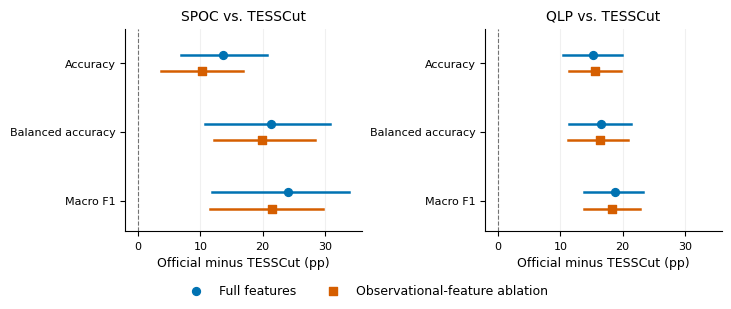

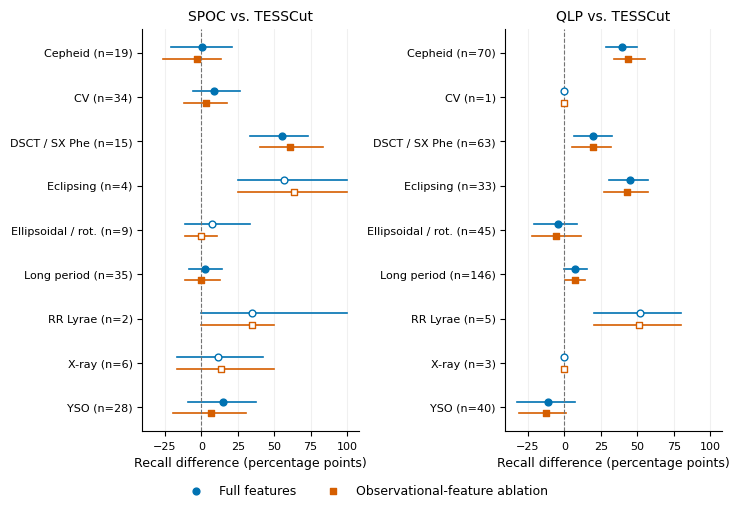

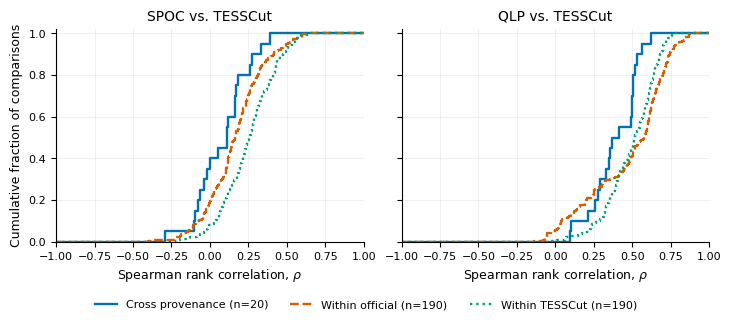

Generated paper figures:
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/paired_metric_gaps_output.pdf
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/paired_metric_gaps_output.png
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/per_class_recall_gaps_output.pdf
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/per_class_recall_gaps_output.png
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/importance_stability_output.pdf
/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/importance_stability_output.png


In [41]:
# Generate the three figures used by the manuscript.
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
})
paper_figure_paths = []

figure, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharex=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    for offset_index, (variant, color, marker) in enumerate(zip(
        ["Full features", "Metadata ablation"], PAPER_COLORS, ["o", "s"]
    )):
        selected = paper_aggregate[
            (paper_aggregate["Comparison"] == comparison)
            & (paper_aggregate["Variant"] == variant)
        ]
        for metric_index, (_, row) in enumerate(selected.iterrows()):
            y = 2 - metric_index + (0.12 if offset_index == 0 else -0.12)
            axis.plot([100 * row["DeltaP025"], 100 * row["DeltaP975"]], [y, y], color=color, lw=1.8)
            display_variant = "Observational-feature ablation" if variant == "Metadata ablation" else variant
            axis.scatter(100 * row["DeltaMean"], y, color=color, marker=marker, s=32,
                         label=display_variant if metric_index == 0 else None, zorder=3)
    axis.axvline(0, color="0.45", lw=0.8, ls="--")
    axis.set(yticks=[2, 1, 0], yticklabels=[item[1] for item in PAPER_METRICS],
             ylim=(-0.45, 2.5), xlim=paper_interval_xlim(paper_aggregate), xlabel="Official minus TESSCut (pp)",
             title=comparison.replace("_vs_", " vs. "))
    axis.grid(axis="x", alpha=0.18)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
paper_figure_paths.extend(save_paper_figure(figure, "paired_metric_gaps_output"))

figure, axes = plt.subplots(1, 2, figsize=(7.2, 5.0), sharex=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    for offset_index, (variant, color, marker) in enumerate(zip(
        ["Full features", "Metadata ablation"], PAPER_COLORS, ["o", "s"]
    )):
        selected = paper_per_class[
            (paper_per_class["Comparison"] == comparison)
            & (paper_per_class["Variant"] == variant)
            & (paper_per_class["Metric"] == "Recall")
        ].set_index("Family")
        for family_index, family in enumerate(PAPER_FAMILIES_BY_COMPARISON[comparison]):
            row = selected.loc[family]
            y = len(PAPER_FAMILIES_BY_COMPARISON[comparison]) - 1 - family_index + (0.13 if offset_index == 0 else -0.13)
            axis.plot([100 * row["DeltaP025"], 100 * row["DeltaP975"]], [y, y], color=color, lw=1.2)
            display_variant = "Observational-feature ablation" if variant == "Metadata ablation" else variant
            axis.scatter(100 * row["DeltaMean"], y,
                         facecolors=color if row["TestSupport"] >= 10 else "white",
                         edgecolors=color, marker=marker, s=24, zorder=3,
                         label=display_variant if family_index == 0 else None)
    labels_for_axis = [
        f"{PAPER_FAMILY_DISPLAY[family]} (n={int(selected.loc[family, 'TestSupport'])})"
        for family in PAPER_FAMILIES_BY_COMPARISON[comparison]
    ]
    axis.set(yticks=list(range(len(PAPER_FAMILIES_BY_COMPARISON[comparison])))[::-1], yticklabels=labels_for_axis,
             xlabel="Recall difference (percentage points)", xlim=paper_interval_xlim(paper_per_class[paper_per_class["Metric"].eq("Recall")]),
             title=comparison.replace("_vs_", " vs. "))
    axis.axvline(0, color="0.45", lw=0.8, ls="--")
    axis.grid(axis="x", alpha=0.18)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
paper_figure_paths.extend(save_paper_figure(figure, "per_class_recall_gaps_output"))

figure, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), sharex=True, sharey=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    official_name = comparison.split("_vs_")[0]
    for correlation_type, color, line_style in zip(
        ["Cross provenance", f"Within {official_name}", "Within TESSCut"],
        PAPER_COLORS, ["-", "--", ":"],
    ):
        values = np.sort(paper_correlations[
            (paper_correlations["Comparison"] == comparison)
            & (paper_correlations["Type"] == correlation_type)
        ]["Rho"].to_numpy())
        label = "Within official" if correlation_type == f"Within {official_name}" else correlation_type
        axis.step(np.r_[-1, values, 1], np.r_[0, np.arange(1, len(values) + 1) / len(values), 1],
                  where="post", color=color, ls=line_style, lw=1.7,
                  label=f"{label} (n={len(values)})")
    axis.set(xlim=(-1, 1), ylim=(0, 1.02), xlabel=r"Spearman rank correlation, $\rho$",
             title=comparison.replace("_vs_", " vs. "))
    axis.grid(alpha=0.18)
axes[0].set_ylabel("Cumulative fraction of comparisons")
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, fontsize=8)
paper_figure_paths.extend(save_paper_figure(figure, "importance_stability_output"))

print("Generated paper figures:")
for path in paper_figure_paths:
    print(path)


In [42]:
# Save and verify a traceability manifest for every paper asset.
paper_asset_manifest = {
    "analysis_name": "Publication paper asset generation",
    "models_refitted": False,
    "source_simulation_manifest": str(manifest_path),
    "source_ablation_manifest": str(ABLATION_MANIFEST_PATH),
    "source_manifest_hashes": trv.file_fingerprints([manifest_path, ABLATION_MANIFEST_PATH]),
    "split_count": int(N_SPLITS),
    "permutation_split_count": int(PERMUTATION_SPLIT_COUNT),
    "full_feature_count": int(len(FULL_FEATURE_COLUMNS)),
    "ablated_feature_count": int(len(ABLATED_FEATURE_COLUMNS)),
    "removed_observational_features": METADATA_LIKE_FEATURES_REMOVED,
    "tables": [str(path) for path in paper_table_paths],
    "figures": [str(path) for path in paper_figure_paths],
    "audit_files": [
        str(PAPER_AUDIT_DIR / "aggregate_metrics_output.csv"),
        str(PAPER_AUDIT_DIR / "per_class_metrics_output.csv"),
        str(PAPER_AUDIT_DIR / "importance_pairwise_correlations_output.csv"),
        str(PAPER_AUDIT_DIR / "importance_correlation_summary_output.csv"),
    ],
}
paper_manifest_path = PAPER_ASSET_ROOT / "paper_asset_manifest.json"
paper_manifest_path.write_text(json.dumps(paper_asset_manifest, indent=2), encoding="utf-8")

expected_table_files = 5
expected_figure_files = 6  # three figures, each in PDF and PNG
assert len(paper_table_paths) == expected_table_files
assert len(paper_figure_paths) == expected_figure_files
assert all(path.exists() and path.stat().st_size > 0 for path in paper_table_paths)
assert all(path.exists() and path.stat().st_size > 0 for path in paper_figure_paths)
assert len(paper_aggregate) == len(PAPER_COMPARISONS) * 2 * len(PAPER_METRICS)
assert len(paper_per_class) == sum(len(families) for families in PAPER_FAMILIES_BY_COMPARISON.values()) * 2 * 2
assert len(paper_correlations[paper_correlations["Type"] == "Cross provenance"]) == len(PAPER_COMPARISONS) * PERMUTATION_SPLIT_COUNT
assert len(paper_correlations[paper_correlations["Type"].str.startswith("Within")]) == len(PAPER_COMPARISONS) * 2 * (PERMUTATION_SPLIT_COUNT * (PERMUTATION_SPLIT_COUNT - 1) // 2)

print("Paper asset traceability verification passed.")
print(f"Manifest: {paper_manifest_path}")
display(pd.DataFrame({
    "Asset type": ["LaTeX tables", "CSV table equivalents", "PDF figures", "PNG figures"],
    "Count": [5, 5, 3, 3],
}))


Paper asset traceability verification passed.
Manifest: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/paper_asset_manifest.json


,Asset type,Count
0,LaTeX tables,5
1,CSV table equivalents,5
2,PDF figures,3
3,PNG figures,3


## 12. Direct regeneration of paper Figures 4, 6, 7, 8, and 9

This section uses the current corrected results loaded and verified above; it does not fit more models or substitute historical values.

- **Figure 4:** seed-42 SPOC–TESSCut impurity-importance rank shifts.
- **Figure 6:** seed-42 QLP–TESSCut impurity-importance rank shifts.
- **Figure 7:** repeated aggregate metric gaps before and after observational-feature ablation.
- **Figure 8:** repeated per-class recall gaps.
- **Figure 9:** cross- and within-provenance permutation-importance rank stability.

Cell 35 exports Figures 4 and 6 on a 3.5-inch canvas as 600-dpi PNGs and vector PDFs. The selected features, ranks, sorting, and plot limits are derived from the corrected results. Historical Python variable names are retained for compatibility; the figure numbers above refer to the current manuscript. Replace the manuscript assets only after the scientific rerun and review.


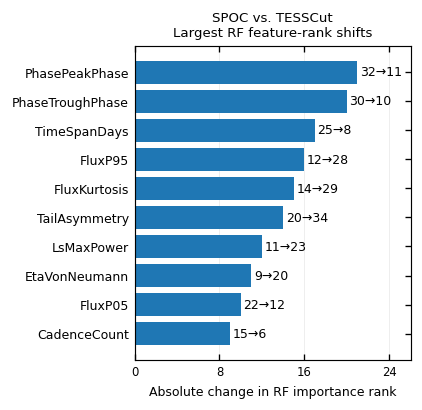

Generated from the same saved seed-42 importance values: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/spoc_tesscut_rf_rank_shifts.png
PNG: 2100 x 2040 pixels; vector PDF: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/spoc_tesscut_rf_rank_shifts.pdf


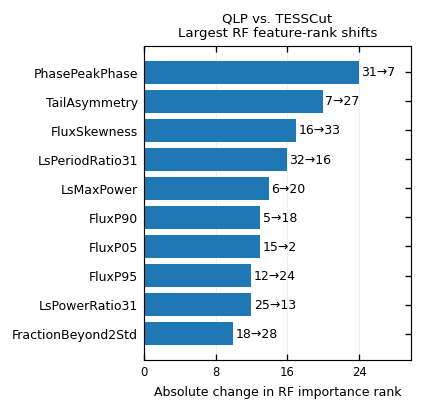

Generated from the same saved seed-42 importance values: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/qlp_tesscut_rf_rank_shifts.png
PNG: 2100 x 2040 pixels; vector PDF: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/qlp_tesscut_rf_rank_shifts.pdf


,Feature,SPOCRFImportance,TESSCutRFImportance,SPOCRank,TESSCutRank,AbsRankChange
0,PhasePeakPhase,0.011045,0.032374,32.0,11.0,21.0
1,PhaseTroughPhase,0.013631,0.032876,30.0,10.0,20.0
2,TimeSpanDays,0.017055,0.034077,25.0,8.0,17.0
3,FluxP95,0.031606,0.022039,12.0,28.0,16.0
4,FluxKurtosis,0.028791,0.021429,14.0,29.0,15.0
5,TailAsymmetry,0.023102,0.018165,20.0,34.0,14.0
6,LsMaxPower,0.034668,0.024191,11.0,23.0,12.0
7,EtaVonNeumann,0.036268,0.027016,9.0,20.0,11.0
8,FluxP05,0.019949,0.031170,22.0,12.0,10.0
9,CadenceCount,0.026799,0.037673,15.0,6.0,9.0


,Feature,QLPRFImportance,TESSCutRFImportance,QLPRank,TESSCutRank,AbsRankChange
0,PhasePeakPhase,0.015914,0.034077,31.0,7.0,24.0
1,TailAsymmetry,0.039432,0.022582,7.0,27.0,20.0
2,FluxSkewness,0.024445,0.020528,16.0,33.0,17.0
3,LsPeriodRatio31,0.015780,0.027677,32.0,16.0,16.0
4,LsMaxPower,0.039640,0.026352,6.0,20.0,14.0
5,FluxP90,0.044140,0.026695,5.0,18.0,13.0
6,FluxP05,0.025824,0.044565,15.0,2.0,13.0
7,FluxP95,0.034682,0.023299,12.0,24.0,12.0
8,LsPowerRatio31,0.019772,0.030871,25.0,13.0,12.0
9,FractionBeyond2Std,0.022625,0.022370,18.0,28.0,10.0


In [43]:
# Figures 4 and 6: representative single-split RF impurity-importance rank shifts.
# Source: saved monte_carlo_rf_feature_importance.parquet, split seed 42.
REPRESENTATIVE_SPLIT_SEED = 42
representative_rf_importance = combined_results["rf_importance"].copy()

required_importance_columns = {
    "Comparison", "SplitSeed", "Provenance", "Feature", "RFImportance"
}
missing_importance_columns = sorted(
    required_importance_columns - set(representative_rf_importance.columns)
)
if missing_importance_columns:
    raise KeyError(
        f"Saved RF-importance output is missing: {missing_importance_columns}"
    )

def build_representative_rank_shift(comparison, official_provenance):
    saved = representative_rf_importance[
        (representative_rf_importance["Comparison"] == comparison)
        & (representative_rf_importance["SplitSeed"] == REPRESENTATIVE_SPLIT_SEED)
    ].copy()
    official = saved[saved["Provenance"] == official_provenance][
        ["Feature", "RFImportance"]
    ].rename(columns={"RFImportance": f"{official_provenance}RFImportance"})
    tesscut = saved[saved["Provenance"] == "TESSCut"][
        ["Feature", "RFImportance"]
    ].rename(columns={"RFImportance": "TESSCutRFImportance"})
    rank_shift = official.merge(tesscut, on="Feature", validate="one_to_one")
    if len(rank_shift) != len(FULL_FEATURE_COLUMNS):
        raise AssertionError(
            f"Expected {len(FULL_FEATURE_COLUMNS)} features for {comparison}; "
            f"found {len(rank_shift)}."
        )
    rank_shift[f"{official_provenance}Rank"] = rank_shift[
        f"{official_provenance}RFImportance"
    ].rank(method="min", ascending=False)
    rank_shift["TESSCutRank"] = rank_shift["TESSCutRFImportance"].rank(
        method="min", ascending=False
    )
    rank_shift["AbsRankChange"] = (
        rank_shift[f"{official_provenance}Rank"] - rank_shift["TESSCutRank"]
    ).abs()
    return rank_shift.sort_values(
        ["AbsRankChange", f"{official_provenance}RFImportance"],
        ascending=[False, False],
    ).reset_index(drop=True)

def plot_representative_rank_shift(comparison, official_provenance, filename, png_dpi=600):
    """Export the same saved rank shifts at a legible, column-sized print scale."""
    from matplotlib.ticker import MaxNLocator

    if int(png_dpi) < 400:
        raise ValueError("Use at least 400 dpi; the default is 600 dpi.")
    rank_shift = build_representative_rank_shift(comparison, official_provenance)
    top_ten = rank_shift.head(10).iloc[::-1].copy()
    style = {
        "font.family": "DejaVu Sans",
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7.5,
        "axes.linewidth": 0.7,
        "text.usetex": False,
        "pdf.fonttype": 42,
        "figure.dpi": 120,
        "savefig.facecolor": "white",
        "savefig.bbox": None,
    }
    with plt.rc_context(style):
        # A native 3.5-inch canvas avoids shrinking large-canvas text in LaTeX.
        figure, axis = plt.subplots(figsize=(3.5, 3.4))
        bars = axis.barh(top_ten["Feature"], top_ten["AbsRankChange"], color="#1f77b4")
        official_rank_column = f"{official_provenance}Rank"
        annotations = []
        for bar, (_, row) in zip(bars, top_ten.iterrows()):
            label = f"{int(row[official_rank_column])}→{int(row['TESSCutRank'])}"
            annotations.append(axis.text(
                bar.get_width() + 0.25, bar.get_y() + bar.get_height() / 2,
                label, va="center", fontsize=7.5,
            ))
        axis.set_title(
            f"{official_provenance} vs. TESSCut\nLargest RF feature-rank shifts",
            fontsize=8,
        )
        axis.set_xlabel("Absolute change in RF importance rank", fontsize=7.5)
        axis.tick_params(axis="x", labelsize=7)
        axis.tick_params(axis="y", labelsize=7.5)
        axis.tick_params(axis="both", direction="in", top=True, right=True)
        for spine in axis.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.7)
        axis.grid(axis="x", alpha=0.25, linewidth=0.5)
        axis.set_axisbelow(True)
        largest_shift = float(top_ten["AbsRankChange"].max())
        axis.set_xlim(0, largest_shift + max(5.0, 0.24 * largest_shift))
        axis.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        figure.tight_layout(pad=0.8)
        figure.canvas.draw()
        renderer = figure.canvas.get_renderer()
        for annotation in annotations:
            bounds = annotation.get_window_extent(renderer)
            if bounds.x1 > axis.bbox.x1:
                raise ValueError("A rank annotation exceeds the axis; increase the horizontal padding.")
        bounds = figure.get_tightbbox(renderer)
        width, height = figure.get_size_inches()
        if (bounds.x0 < -0.03 or bounds.y0 < -0.03
                or bounds.x1 > width + 0.03 or bounds.y1 > height + 0.03):
            raise ValueError("A rank-plot label extends outside the canvas; review the layout.")
        output_path = PAPER_ASSET_ROOT / filename
        output_path.parent.mkdir(parents=True, exist_ok=True)
        pdf_path = output_path.with_suffix(".pdf")
        figure.savefig(output_path, dpi=int(png_dpi), bbox_inches=None, facecolor="white")
        figure.savefig(pdf_path, bbox_inches=None, facecolor="white")
        plt.show()
        plt.close(figure)
    print(f"Generated from the same saved seed-42 importance values: {output_path}")
    print(f"PNG: {round(3.5 * int(png_dpi))} x {round(3.4 * int(png_dpi))} pixels; vector PDF: {pdf_path}")
    return output_path, rank_shift

# Legacy variable names are retained for compatibility with later cells.
figure_5_path, figure_5_rank_data = plot_representative_rank_shift(
    "SPOC_vs_TESSCut", "SPOC", "spoc_tesscut_rf_rank_shifts.png"
)
figure_7_path, figure_7_rank_data = plot_representative_rank_shift(
    "QLP_vs_TESSCut", "QLP", "qlp_tesscut_rf_rank_shifts.png"
)
display(figure_5_rank_data.head(10))
display(figure_7_rank_data.head(10))

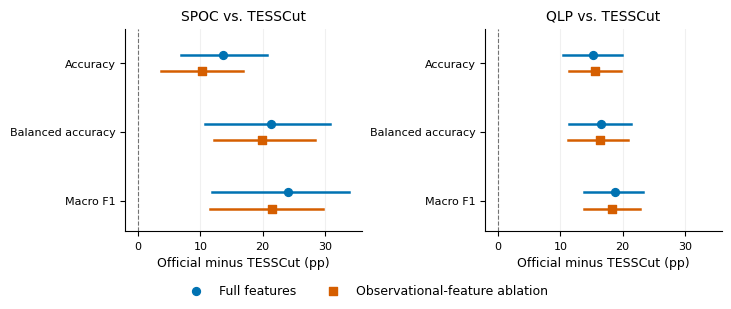

Figure 7 regenerated from saved aggregate summaries: (PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/paired_metric_gaps_output.pdf'), PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/paired_metric_gaps_output.png'))


In [44]:
# Figure 7: paired aggregate performance gaps over 100 saved splits.
figure, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), sharex=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    for offset_index, (variant, color, marker) in enumerate(zip(
        ["Full features", "Metadata ablation"], PAPER_COLORS, ["o", "s"]
    )):
        selected = paper_aggregate[
            (paper_aggregate["Comparison"] == comparison)
            & (paper_aggregate["Variant"] == variant)
        ]
        for metric_index, (_, row) in enumerate(selected.iterrows()):
            y = 2 - metric_index + (0.12 if offset_index == 0 else -0.12)
            axis.plot(
                [100 * row["DeltaP025"], 100 * row["DeltaP975"]],
                [y, y], color=color, lw=1.8,
            )
            display_variant = (
                "Observational-feature ablation"
                if variant == "Metadata ablation" else variant
            )
            axis.scatter(
                100 * row["DeltaMean"], y, color=color, marker=marker, s=32,
                label=display_variant if metric_index == 0 else None, zorder=3,
            )
    axis.axvline(0, color="0.45", lw=0.8, ls="--")
    axis.set(
        yticks=[2, 1, 0], yticklabels=[item[1] for item in PAPER_METRICS],
        ylim=(-0.45, 2.5), xlim=paper_interval_xlim(paper_aggregate),
        xlabel="Official minus TESSCut (pp)",
        title=comparison.replace("_vs_", " vs. "),
    )
    axis.grid(axis="x", alpha=0.18)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
figure_8_paths = save_paper_figure(figure, "paired_metric_gaps_output")
print(f"Figure 7 regenerated from saved aggregate summaries: {figure_8_paths}")


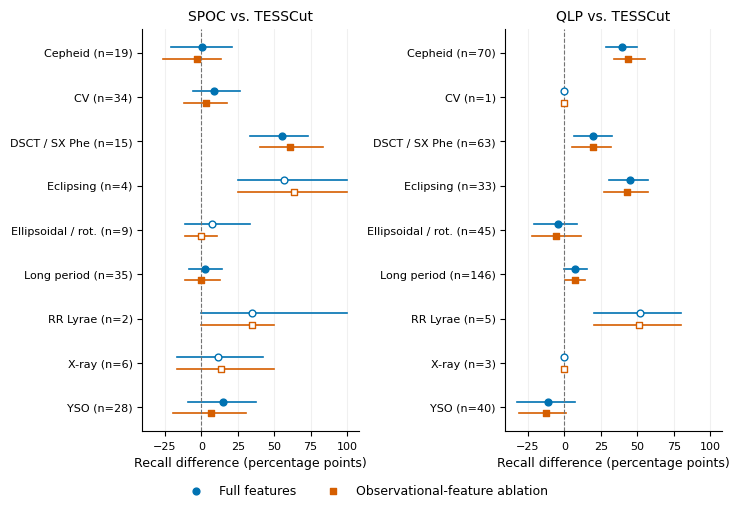

Figure 8 regenerated from saved per-class summaries: (PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/per_class_recall_gaps_output.pdf'), PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/per_class_recall_gaps_output.png'))


In [45]:
# Figure 8: per-class recall differences over 100 saved splits.
figure, axes = plt.subplots(1, 2, figsize=(7.2, 5.0), sharex=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    label_source = None
    for offset_index, (variant, color, marker) in enumerate(zip(
        ["Full features", "Metadata ablation"], PAPER_COLORS, ["o", "s"]
    )):
        selected = paper_per_class[
            (paper_per_class["Comparison"] == comparison)
            & (paper_per_class["Variant"] == variant)
            & (paper_per_class["Metric"] == "Recall")
        ].set_index("Family")
        label_source = selected
        for family_index, family in enumerate(PAPER_FAMILIES_BY_COMPARISON[comparison]):
            row = selected.loc[family]
            y = len(PAPER_FAMILIES_BY_COMPARISON[comparison]) - 1 - family_index + (
                0.13 if offset_index == 0 else -0.13
            )
            axis.plot(
                [100 * row["DeltaP025"], 100 * row["DeltaP975"]],
                [y, y], color=color, lw=1.2,
            )
            display_variant = (
                "Observational-feature ablation"
                if variant == "Metadata ablation" else variant
            )
            axis.scatter(
                100 * row["DeltaMean"], y,
                facecolors=color if row["TestSupport"] >= 10 else "white",
                edgecolors=color, marker=marker, s=24, zorder=3,
                label=display_variant if family_index == 0 else None,
            )
    labels_for_axis = [
        f"{PAPER_FAMILY_DISPLAY[family]} (n={int(label_source.loc[family, 'TestSupport'])})"
        for family in PAPER_FAMILIES_BY_COMPARISON[comparison]
    ]
    axis.set(
        yticks=list(range(len(PAPER_FAMILIES_BY_COMPARISON[comparison])))[::-1],
        yticklabels=labels_for_axis,
        xlabel="Recall difference (percentage points)",
        xlim=paper_interval_xlim(paper_per_class[paper_per_class["Metric"].eq("Recall")]), title=comparison.replace("_vs_", " vs. "),
    )
    axis.axvline(0, color="0.45", lw=0.8, ls="--")
    axis.grid(axis="x", alpha=0.18)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
figure_9_paths = save_paper_figure(figure, "per_class_recall_gaps_output")
print(f"Figure 8 regenerated from saved per-class summaries: {figure_9_paths}")


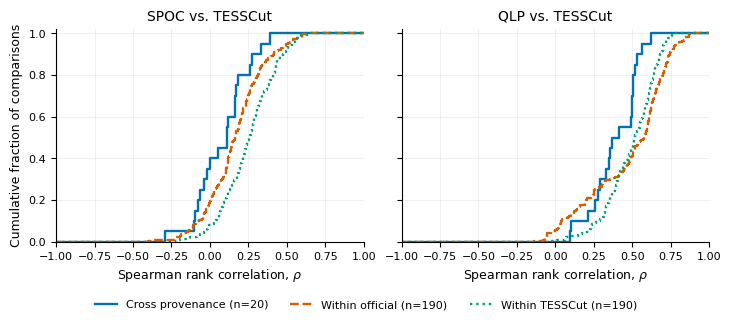

Figure 9 regenerated from saved rank correlations: (PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/importance_stability_output.pdf'), PosixPath('/data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/figures_output/importance_stability_output.png'))


In [46]:
# Figure 9: empirical distributions of saved importance-rank correlations.
figure, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), sharex=True, sharey=True, layout="constrained")
for axis, comparison in zip(axes, PAPER_COMPARISONS):
    official_name = comparison.split("_vs_")[0]
    for correlation_type, color, line_style in zip(
        ["Cross provenance", f"Within {official_name}", "Within TESSCut"],
        PAPER_COLORS, ["-", "--", ":"],
    ):
        values = np.sort(paper_correlations[
            (paper_correlations["Comparison"] == comparison)
            & (paper_correlations["Type"] == correlation_type)
        ]["Rho"].to_numpy())
        if len(values) == 0:
            raise AssertionError(f"No saved correlations for {comparison}, {correlation_type}.")
        label = (
            "Within official"
            if correlation_type == f"Within {official_name}" else correlation_type
        )
        axis.step(
            np.r_[-1, values, 1],
            np.r_[0, np.arange(1, len(values) + 1) / len(values), 1],
            where="post", color=color, ls=line_style, lw=1.7,
            label=f"{label} (n={len(values)})",
        )
    axis.set(
        xlim=(-1, 1), ylim=(0, 1.02),
        xlabel=r"Spearman rank correlation, $\rho$",
        title=comparison.replace("_vs_", " vs. "),
    )
    axis.grid(alpha=0.18)
axes[0].set_ylabel("Cumulative fraction of comparisons")
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(
    handles, labels, loc="outside lower center", ncol=3,
    frameon=False, fontsize=8,
)
figure_10_paths = save_paper_figure(figure, "importance_stability_output")
print(f"Figure 9 regenerated from saved rank correlations: {figure_10_paths}")


In [47]:
# Verify and record the exact saved-result source for each regenerated figure.
paper_figure_traceability = pd.DataFrame([
    {"PaperFigure": 4, "Output": str(figure_5_path), "VectorPDF": str(figure_5_path.with_suffix(".pdf")),
     "SavedSource": str(output_files["rf_importance"]),
     "Selection": "SPOC_vs_TESSCut, SplitSeed=42, RFImportance"},
    {"PaperFigure": 6, "Output": str(figure_7_path), "VectorPDF": str(figure_7_path.with_suffix(".pdf")),
     "SavedSource": str(output_files["rf_importance"]),
     "Selection": "QLP_vs_TESSCut, SplitSeed=42, RFImportance"},
    {"PaperFigure": 7, "Output": str(figure_8_paths[0]),
     "VectorPDF": str(figure_8_paths[0]),
     "SavedSource": str(PAPER_AUDIT_DIR / "aggregate_metrics_output.csv"),
     "Selection": "100 paired splits, aggregate metrics"},
    {"PaperFigure": 8, "Output": str(figure_9_paths[0]),
     "VectorPDF": str(figure_9_paths[0]),
     "SavedSource": str(PAPER_AUDIT_DIR / "per_class_metrics_output.csv"),
     "Selection": "100 paired splits, class recall"},
    {"PaperFigure": 9, "Output": str(figure_10_paths[0]),
     "VectorPDF": str(figure_10_paths[0]),
     "SavedSource": str(PAPER_AUDIT_DIR / "importance_pairwise_correlations_output.csv"),
     "Selection": "20 selected splits; cross/within rank correlations"},
])
traceability_path = PAPER_AUDIT_DIR / "paper_figure_traceability_output.csv"
paper_figure_traceability.to_csv(traceability_path, index=False)
figure_files = [
    figure_5_path, figure_7_path, figure_5_path.with_suffix(".pdf"),
    figure_7_path.with_suffix(".pdf"), *figure_8_paths, *figure_9_paths, *figure_10_paths
]
assert all(path.exists() and path.stat().st_size > 0 for path in figure_files)
assert len(figure_5_rank_data) == len(FULL_FEATURE_COLUMNS)
assert len(figure_7_rank_data) == len(FULL_FEATURE_COLUMNS)
print("Figures 4, 6, 7, 8, and 9 regenerated without model fitting.")
print(f"Traceability table: {traceability_path}")
display(paper_figure_traceability)

Figures 4, 6, 7, 8, and 9 regenerated without model fitting.
Traceability table: /data/projects/TESS_Research_Publication/results/controlled_analysis/paper_assets_output/analysis_output/paper_figure_traceability_output.csv


,PaperFigure,Output,VectorPDF,SavedSource,Selection
0,4,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,"SPOC_vs_TESSCut, SplitSeed=42, RFImportance"
1,6,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,"QLP_vs_TESSCut, SplitSeed=42, RFImportance"
2,7,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,"100 paired splits, aggregate metrics"
3,8,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,"100 paired splits, class recall"
4,9,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,/data/projects/TESS_Research_Publication/resul...,20 selected splits; cross/within rank correlat...


## 13. Split-selection and prefix stability diagnostics

Run the preceding configuration, pairing, and result verification sections first. This cell validates the current full-feature cache and reads its paired-split summary and permutation-seed records. It does not retrain models or recompute permutation importance.

The selected 20 permutation-importance splits are compared descriptively with all 100 and the remaining 80. Prefixes of 25, 50, 75, and 100 scheduled splits additionally show how means and empirical percentile ranges evolve for product metrics and paired provenance gaps. No stopping rule or seed selection is adjusted in response to these diagnostics.

The splits reuse stars, so these summaries do not prove that 100 splits are statistically sufficient or supply independent-sample confidence intervals. Similar product performance also does not establish representative feature-importance rankings. Diagnostic outputs go to `OUTPUT_DIR / "permutation_split_performance_check"`.


In [48]:
# Requires the preceding corrected input preparation and manifest configuration.
required_state = ["OUTPUT_DIR", "ANALYSIS_INPUT_FILES", "RUN_CONFIG", "output_files", "manifest_path"]
missing_state = [name for name in required_state if name not in globals()]
if missing_state:
    raise RuntimeError("Run the preceding configuration, pairing, and result-verification sections first.")
if not trv.run_cache_is_current(manifest_path, inputs=ANALYSIS_INPUT_FILES, config=RUN_CONFIG, outputs=list(output_files.values())):
    raise RuntimeError("The saved full-feature analysis is stale; rerun notebook 04 before these diagnostics.")

SPLIT_CHECK_OUTPUT_DIR = OUTPUT_DIR / "permutation_split_performance_check"
summary_file = output_files["paired_summary"]
importance_file = output_files["permutation_importance_summary"]
manifest_file = manifest_path
split_check = pd.read_csv(summary_file)
importance_check = pd.read_csv(importance_file, usecols=["Comparison", "Provenance", "SplitSeed"])
saved_manifest = json.loads(manifest_file.read_text(encoding="utf-8"))["config"]
all_seeds = [int(s) for s in saved_manifest["split_seeds"]]
selected_seeds = [int(s) for s in saved_manifest["repeated_permutation_importance"]["split_seeds"]]
expected_selected = np.array(all_seeds)[np.linspace(0, len(all_seeds)-1, 20, dtype=int)].tolist()
if len(all_seeds) != 100 or len(set(all_seeds)) != 100:
    raise ValueError("Expected 100 distinct split seeds in the saved manifest.")
if len(selected_seeds) != 20 or len(set(selected_seeds)) != 20 or selected_seeds != expected_selected:
    raise ValueError("Saved permutation seeds do not match the prespecified 20 evenly spaced schedule positions.")

metrics = {"Accuracy": "Accuracy", "BalancedAccuracy": "Balanced accuracy", "MacroF1": "Macro F1"}
required_columns = ["Comparison", "SplitSeed"] + [prefix + metric for metric in metrics for prefix in ["OfficialTest", "TESSCutTest", "DeltaTest"]]
missing_columns = set(required_columns) - set(split_check.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")
if split_check.duplicated(["Comparison", "SplitSeed"]).any():
    raise ValueError("Duplicate comparison/seed rows in saved summary.")
if set(split_check["Comparison"]) != {"SPOC_vs_TESSCut", "QLP_vs_TESSCut"}:
    raise ValueError("Unexpected comparisons in saved summary.")

summary_rows, difference_rows = [], []
for comparison, group in split_check.groupby("Comparison", sort=False):
    if len(group) != 100 or set(group["SplitSeed"]) != set(all_seeds):
        raise ValueError(f"Incomplete 100-split results for {comparison}.")
    official = comparison.split("_vs_")[0]
    for provenance in [official, "TESSCut"]:
        observed = importance_check[(importance_check["Comparison"] == comparison) & (importance_check["Provenance"] == provenance)]
        if set(observed["SplitSeed"]) != set(selected_seeds):
            raise ValueError(f"Actual saved permutation seeds disagree with manifest: {comparison}, {provenance}.")
    selected = group[group["SplitSeed"].isin(selected_seeds)]
    remaining = group[~group["SplitSeed"].isin(selected_seeds)]
    for metric, label in metrics.items():
        if not np.allclose(group["DeltaTest"+metric], group["OfficialTest"+metric] - group["TESSCutTest"+metric]):
            raise ValueError(f"Paired gap mismatch: {comparison}, {metric}.")
        for prefix, outcome in [("OfficialTest", official), ("TESSCutTest", "TESSCut"), ("DeltaTest", "Official minus TESSCut")]:
            column = prefix + metric
            if not np.isfinite(group[column].to_numpy(dtype=float)).all():
                raise ValueError(f"Nonfinite saved values: {comparison}, {column}.")
            for subset_name, frame in [("All 100", group), ("Selected 20", selected), ("Remaining 80", remaining)]:
                values = frame[column] * 100
                summary_rows.append({"Comparison": comparison, "Metric": label, "Outcome": outcome,
                    "Subset": subset_name, "Splits": len(values), "Mean_pp": values.mean(),
                    "SD_pp": values.std(ddof=1), "Median_pp": values.median(),
                    "P025_pp": values.quantile(.025), "P975_pp": values.quantile(.975),
                    "Min_pp": values.min(), "Max_pp": values.max()})
            difference_rows.append({"Comparison": comparison, "Metric": label, "Outcome": outcome,
                "Mean_all100_pp": 100*group[column].mean(),
                "Mean_selected20_pp": 100*selected[column].mean(),
                "Selected20_minus_all100_pp": 100*(selected[column].mean()-group[column].mean()),
                "Selected20_minus_remaining80_pp": 100*(selected[column].mean()-remaining[column].mean())})

split_check_summary = pd.DataFrame(summary_rows)
split_check_differences = pd.DataFrame(difference_rows)
SPLIT_CHECK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
split_check_summary.to_csv(SPLIT_CHECK_OUTPUT_DIR / "performance_distribution_summary.csv", index=False)
split_check_differences.to_csv(SPLIT_CHECK_OUTPUT_DIR / "performance_mean_differences.csv", index=False)
selection_record = split_check.copy()
selection_record["SelectedForPermutation"] = selection_record["SplitSeed"].isin(selected_seeds)
selection_record.to_csv(SPLIT_CHECK_OUTPUT_DIR / "split_selection_and_saved_metrics.csv", index=False)
prefix_rows = []
for comparison, group in split_check.groupby("Comparison", sort=False):
    ordered = group.set_index("SplitSeed").loc[all_seeds]
    official = comparison.split("_vs_")[0]
    for prefix_count in [25, 50, 75, 100]:
        prefix_frame = ordered.iloc[:prefix_count]
        for metric, label in metrics.items():
            for column_prefix, outcome in [("OfficialTest", official), ("TESSCutTest", "TESSCut"), ("DeltaTest", "Official minus TESSCut")]:
                column = column_prefix + metric
                values = 100 * prefix_frame[column]
                prefix_rows.append({
                    "Comparison": comparison, "Metric": label, "Outcome": outcome,
                    "PrefixSplits": prefix_count, "FirstSeed": all_seeds[0], "LastSeed": all_seeds[prefix_count - 1],
                    "Mean_pp": values.mean(), "SD_pp": values.std(ddof=1),
                    "P025_pp": values.quantile(.025), "P975_pp": values.quantile(.975),
                    "Mean_minus_all100_pp": values.mean() - 100 * ordered[column].mean(),
                })
prefix_stability = pd.DataFrame(prefix_rows)
prefix_stability.to_csv(SPLIT_CHECK_OUTPUT_DIR / "prefix_split_stability_summary.csv", index=False)
audit = {
    "source_files": trv.file_fingerprints([summary_file, importance_file, manifest_file]),
    "all_seeds": all_seeds, "selected_seeds": selected_seeds, "prefix_split_counts": [25, 50, 75, 100],
    "units": "Metrics multiplied by 100; mean differences in percentage points",
    "analysis": "Descriptive comparisons of corrected full-feature results; no model fitting or permutation recomputation",
}
(SPLIT_CHECK_OUTPUT_DIR / "source_and_selection_record.json").write_text(json.dumps(audit, indent=2))
print("Verified the selected seeds against the saved permutation results:", selected_seeds)
print("Metrics below are multiplied by 100. Differences and SDs are in percentage points.")
print("Distribution summaries (percentile ranges describe splits, not confidence intervals):")
print(split_check_summary.round(4).to_string(index=False))
print("\nDifferences between subset means:")
print(split_check_differences.round(4).to_string(index=False))
for comparison, rows in split_check_differences.groupby("Comparison", sort=False):
    gap = rows["Outcome"].eq("Official minus TESSCut")
    x = rows.loc[~gap, "Selected20_minus_all100_pp"].abs().max()
    y = rows.loc[gap, "Selected20_minus_all100_pp"].abs().max()
    print(f"\n{comparison}: largest absolute selected-20 versus all-100 mean difference = {x:.4f} percentage points for product metrics; {y:.4f} percentage points for paired gaps.")
print("\nDescriptive check only: the selected 20 are part of the full 100, and splits reuse stars. No independent-sample significance test is applied. Similar performance would not establish representative feature-importance rankings. The original selected seeds are unchanged.")
print("\nPrefix stability at 25, 50, 75, and 100 scheduled splits (descriptive):")
print(prefix_stability.round(4).to_string(index=False))
print("Saved diagnostic outputs to:", SPLIT_CHECK_OUTPUT_DIR)


Verified the selected seeds against the saved permutation results: [42, 47, 52, 57, 62, 68, 73, 78, 83, 88, 94, 99, 104, 109, 114, 120, 125, 130, 135, 141]
Metrics below are multiplied by 100. Differences and SDs are in percentage points.
Distribution summaries (percentile ranges describe splits, not confidence intervals):
     Comparison            Metric                Outcome       Subset  Splits  Mean_pp  SD_pp  Median_pp  P025_pp  P975_pp  Min_pp  Max_pp
SPOC_vs_TESSCut          Accuracy                   SPOC      All 100     100  76.5592 2.5293    76.3158  71.3651  80.9211 71.0526 82.2368
SPOC_vs_TESSCut          Accuracy                   SPOC  Selected 20      20  76.6776 1.9618    76.3158  73.6513  80.2961 73.0263 80.9211
SPOC_vs_TESSCut          Accuracy                   SPOC Remaining 80      80  76.5296 2.6622    76.6447  71.0526  80.9375 71.0526 82.2368
SPOC_vs_TESSCut          Accuracy                TESSCut      All 100     100  62.8487 3.4210    63.1579  56.8914  68.1